In [1]:
# Celda 1: librerías, semillas y versiones

import os
import re
import io
import time
import zlib
import random
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import spacy
import torch
import torch.nn as nn
import gensim
import sklearn
import scipy

from collections import Counter
from IPython.display import display
from scipy import sparse
from scipy.stats import spearmanr
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from gensim.models import Word2Vec, FastText, KeyedVectors
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 220)
os.makedirs('figuras', exist_ok=True)

print("gensim:", gensim.__version__)
print("scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("NLTK:", nltk.__version__)
print("spaCy:", spacy.__version__)
print("NumPy:", np.__version__, "| SciPy:", scipy.__version__, "| pandas:", pd.__version__)

gensim: 4.4.0
scikit-learn: 1.9.0
PyTorch: 2.14.1
NLTK: 3.10.0
spaCy: 3.8.14
NumPy: 2.5.1 | SciPy: 1.18.0 | pandas: 3.0.5


# Sección 1: preparación de los corpus

In [2]:
# Celda 2: carga y limpieza del corpus de noticias

df_noticias = pd.read_csv('df_total.csv')
print("Documentos originales:", df_noticias.shape[0])

df_noticias = df_noticias.drop_duplicates(subset='news').dropna(subset=['news']).reset_index(drop=True)
print("Documentos después de limpiar:", df_noticias.shape[0])
print("Categorías:", df_noticias['Type'].nunique())

documentos_en_blanco = (df_noticias['news'].str.strip() == '').sum()
print("Documentos con texto en blanco que siguen en el corpus:", documentos_en_blanco)

Documentos originales: 1217
Documentos después de limpiar: 1138
Categorías: 7
Documentos con texto en blanco que siguen en el corpus: 1


In [3]:
# Celda 3: carga del Quijote, quitar encabezado de Gutenberg y separar capítulos

with open('don-quijote.txt', encoding='utf-8-sig') as archivo:
    texto_quijote_crudo = archivo.read().replace('\r\n', '\n')

inicio_gutenberg = texto_quijote_crudo.index('*** START OF THIS PROJECT GUTENBERG EBOOK')
fin_gutenberg = texto_quijote_crudo.index('*** END OF THIS PROJECT GUTENBERG EBOOK')
texto_quijote = texto_quijote_crudo[inicio_gutenberg:fin_gutenberg]

texto_quijote = texto_quijote[texto_quijote.index('Primera parte del ingenioso hidalgo'):]

texto_quijote = re.sub(r'(?m)^(Primera|Segunda) parte del ingenioso.*\n', '', texto_quijote)

capitulos_quijote = re.split(r'(?m)^(?=Capítulo (?:[Pp]rimero|[IVXLC]+)\.)', texto_quijote)
capitulos_quijote = [capitulo for capitulo in capitulos_quijote if capitulo.startswith('Capítulo')]

print("Caracteres del archivo original:", len(texto_quijote_crudo))
print("Caracteres de la novela sin encabezados:", len(texto_quijote))
print("Capítulos detectados:", len(capitulos_quijote))
print("Primer capítulo:", capitulos_quijote[0][:80].replace('\n', ' '))
print("Último capítulo:", capitulos_quijote[-1][:80].replace('\n', ' '))

Caracteres del archivo original: 2117497
Caracteres de la novela sin encabezados: 2071161
Capítulos detectados: 126
Primer capítulo: Capítulo primero. Que trata de la condición y ejercicio del famoso hidalgo don Q
Último capítulo: Capítulo LXXIV. De cómo don Quijote cayó malo, y del testamento que hizo, y su m


In [4]:
# Celda 4: segmentación en oraciones y tokenización de los dos corpus

patron_token_valido = re.compile(r'^(?:[a-záéíóúüñ]+|\d+)$')

def construir_corpus(textos_documentos):
    estadisticas = {'tokens_crudos': 0, 'tokens_conservados': 0, 'oraciones_descartadas': 0}
    documentos_oraciones = []

    for texto in textos_documentos:
        oraciones_documento = []

        for parrafo in re.split(r'\n\s*\n', texto):
            parrafo = re.sub(r'\s+', ' ', parrafo).strip()
            if not parrafo:
                continue

            for oracion in sent_tokenize(parrafo, language='spanish'):
                tokens_crudos = word_tokenize(oracion, language='spanish')
                tokens = [token.lower() for token in tokens_crudos]
                tokens = [token for token in tokens if patron_token_valido.match(token)]

                estadisticas['tokens_crudos'] += len(tokens_crudos)

                if len(tokens) >= 2:
                    oraciones_documento.append(tokens)
                    estadisticas['tokens_conservados'] += len(tokens)
                else:
                    estadisticas['oraciones_descartadas'] += 1

        documentos_oraciones.append(oraciones_documento)

    return documentos_oraciones, estadisticas

documentos_noticias, estadisticas_noticias = construir_corpus(df_noticias['news'])
documentos_quijote, estadisticas_quijote = construir_corpus(capitulos_quijote)

oraciones_noticias = [oracion for documento in documentos_noticias for oracion in documento]
oraciones_quijote = [oracion for documento in documentos_quijote for oracion in documento]

print("Noticias:", estadisticas_noticias)
print("Quijote:", estadisticas_quijote)
print()
print("Ejemplo de oración de noticias:", oraciones_noticias[3])
print("Ejemplo de oración del Quijote:", oraciones_quijote[3])

Noticias: {'tokens_crudos': 631482, 'tokens_conservados': 588216, 'oraciones_descartadas': 71}
Quijote: {'tokens_crudos': 433555, 'tokens_conservados': 368258, 'oraciones_descartadas': 274}

Ejemplo de oración de noticias: ['la', 'sostenibilidad', 'nos', 'abre', 'oportunidades', 'a', 'mejores', 'fuentes', 'de', 'financiamiento', 'directivo', 'argumentó', 'que', 'lo', 'que', 'se', 'encuentra', 'en', 'juego', 'acá', 'no', 'es', 'un', 'tema', 'de', 'rentabilidad', 'o', 'de', 'negocios', 'en', 'particular', 'es', 'un', 'tema', 'de', 'viabilidad', 'del', 'mundo', 'de', 'los', 'negocios', 'y', 'del', 'mundo', 'físico', 'en', 'general', 'como', 'lo', 'conocemos']
Ejemplo de oración del Quijote: ['una', 'olla', 'de', 'algo', 'más', 'vaca', 'que', 'carnero', 'salpicón', 'las', 'más', 'noches', 'duelos', 'y', 'quebrantos', 'los', 'sábados', 'lantejas', 'los', 'viernes', 'algún', 'palomino', 'de', 'añadidura', 'los', 'domingos', 'consumían', 'las', 'tres', 'partes', 'de', 'su', 'hacienda']


In [5]:
# Celda 5: tabla de documentos, oraciones, tokens y tipos por corpus

def resumen_corpus(nombre, documentos, oraciones):
    tokens = [token for oracion in oraciones for token in oracion]
    return {
        'Corpus': nombre,
        'Documentos': len(documentos),
        'Oraciones': len(oraciones),
        'Tokens': len(tokens),
        'Tipos': len(set(tokens)),
        'Tokens por oración': round(len(tokens) / len(oraciones), 2)
    }

tabla_corpus = pd.DataFrame([
    resumen_corpus('Noticias', documentos_noticias, oraciones_noticias),
    resumen_corpus('Quijote (capítulos)', documentos_quijote, oraciones_quijote)
]).set_index('Corpus')

tabla_corpus

,Documentos,Oraciones,Tokens,Tipos,Tokens por oración
Corpus,,,,,
Noticias,1138,14388,588216,28461,40.88
Quijote (capítulos),126,10391,368258,22443,35.44


In [6]:
# Celda 6: vocabulario con min_count = 1, 2 y 5

def tabla_min_count(nombre, oraciones):
    frecuencias = Counter(token for oracion in oraciones for token in oracion)
    total_tokens = sum(frecuencias.values())
    filas = []

    for minimo in (1, 2, 5):
        tamano_vocabulario = sum(1 for frecuencia in frecuencias.values() if frecuencia >= minimo)
        tokens_fuera = sum(frecuencia for frecuencia in frecuencias.values() if frecuencia < minimo)
        filas.append({
            'Corpus': nombre,
            'min_count': minimo,
            'Tamaño del vocabulario': tamano_vocabulario,
            'Tokens fuera': tokens_fuera,
            '% de tokens fuera': round(tokens_fuera / total_tokens * 100, 2)
        })

    return pd.DataFrame(filas)

tabla_vocabulario = pd.concat([
    tabla_min_count('Noticias', oraciones_noticias),
    tabla_min_count('Quijote', oraciones_quijote)
]).set_index(['Corpus', 'min_count'])

tabla_vocabulario

Tamaño del vocabulario  Tokens fuera  % de tokens fuera
Corpus   min_count                                                         
Noticias 1                           28461             0               0.00
         2                           16131         12330               2.10
         5                            8347         33044               5.62
Quijote  1                           22443             0               0.00
         2                           11515         10928               2.97
         5                            5220         27400               7.44

In [7]:
# Celda 7: carga de fastText SUC (una sola vez) y revisión de mayúsculas, tildes y números

ruta_suc = 'embeddings-m-model.vec'

if os.path.exists(ruta_suc):
    inicio = time.time()
    suc = KeyedVectors.load_word2vec_format(ruta_suc, limit=200_000)
    print(f"SUC cargado en {time.time() - inicio:.1f} segundos")
    print("Palabras en el vocabulario cargado:", len(suc.key_to_index))
    print("Dimensión de los vectores:", suc.vector_size)
else:
    suc = None
    print("No se encontró embeddings-m-model.vec, se sigue sin SUC")

if suc is not None:
    print()
    for palabra in ['españa', 'España', 'espana', 'ESPAÑA', 'gobierno', 'Gobierno', 'tecnología', 'tecnologia', '2019', '1']:
        print(f"{palabra!r:15} en SUC: {palabra in suc.key_to_index}")

    palabras_con_mayuscula = [palabra for palabra in suc.index_to_key if palabra != palabra.lower()]
    print()
    print("Palabras de SUC con alguna mayúscula:", len(palabras_con_mayuscula))
    print("Primeras 15 palabras de SUC:", suc.index_to_key[:15])

SUC cargado en 5.4 segundos
Palabras en el vocabulario cargado: 200000
Dimensión de los vectores: 100

'españa'        en SUC: True
'España'        en SUC: False
'espana'        en SUC: True
'ESPAÑA'        en SUC: False
'gobierno'      en SUC: True
'Gobierno'      en SUC: False
'tecnología'    en SUC: True
'tecnologia'    en SUC: True
'2019'          en SUC: True
'1'             en SUC: True

Palabras de SUC con alguna mayúscula: 0
Primeras 15 palabras de SUC: ['</s>', '.', 'de', ',', 'la', 'que', 'el', 'en', 'y', 'a', 'no', '?', '¿', 'los', 'un']


In [8]:
# Celda 8: qué tanto cubre SUC a mi normalización

def cobertura_en_suc(nombre, oraciones):
    tokens = [token for oracion in oraciones for token in oracion]
    tipos = set(tokens)
    tokens_en_suc = sum(1 for token in tokens if token in suc.key_to_index)
    tipos_en_suc = sum(1 for tipo in tipos if tipo in suc.key_to_index)
    return {
        'Corpus': nombre,
        '% de tokens en SUC': round(tokens_en_suc / len(tokens) * 100, 2),
        '% de tipos en SUC': round(tipos_en_suc / len(tipos) * 100, 2)
    }

if suc is not None:
    tabla_cobertura_suc = pd.DataFrame([
        cobertura_en_suc('Noticias', oraciones_noticias),
        cobertura_en_suc('Quijote', oraciones_quijote)
    ]).set_index('Corpus')
    display(tabla_cobertura_suc)

    frecuencias_noticias_completas = Counter(token for oracion in oraciones_noticias for token in oracion)
    faltantes = [(token, frecuencia) for token, frecuencia in frecuencias_noticias_completas.most_common(3000)
                 if token not in suc.key_to_index]
    print("Tokens de noticias entre los 3000 más frecuentes que no están en SUC:", len(faltantes))
    print(faltantes[:15])

,% de tokens en SUC,% de tipos en SUC
Corpus,,
Noticias,98.86,87.57
Quijote,97.40,73.92


Tokens de noticias entre los 3000 más frecuentes que no están en SUC: 18
[('fintech', 110), ('bancolombia', 107), ('descarbonización', 78), ('criptoactivos', 53), ('colpatria', 43), ('davivienda', 42), ('creg', 41), ('prepandemia', 39), ('covid', 34), ('ngeu', 30), ('banxico', 30), ('rappi', 27), ('bvc', 26), ('corficolombiana', 26), ('scaleups', 25)]


**Normalización que usé para entrenar embeddings**

Pasé todo a minúsculas, quité la puntuación y dejé las tildes tal cual. Los números enteros los dejé como token y los decimales o tokens mezclados con letras los descarté. No quité stopwords y no lematicé.

Revisé el vocabulario de SUC y es todo en minúsculas, pero sí distingue tildes: "españa" está (posición 541), "España" no está y "espana" sí aparece, pero como una variante rara. Además SUC tiene números como tokens ("2019" y "1" están), por eso decidí conservar los enteros. Con esta normalización SUC cubre el 98.86% de los tokens de las noticias (87.57% de los tipos) y el 97.40% de los tokens del Quijote (73.92% de los tipos). Entre las 3000 palabras más frecuentes de las noticias solo faltan 18 en SUC, y son cosas como fintech, bancolombia, descarbonización y covid, o sea palabras muy modernas o de la región.

No quité stopwords porque son parte de la ventana de contexto. En el Lab 1 quitar stopwords bajó los tokens de 631,481 a 318,949, casi la mitad, y eso cambia por completo quién queda al lado de quién. Además word2vec ya submuestrea las palabras muy frecuentes con el parámetro sample. Tampoco lematicé, porque en el Lab 1 la lematización bajó los tipos de 35,931 a 28,801 al juntar plural, singular y conjugaciones, y si "gobiernos" y "gobernó" quedan en una sola forma se pierde justo la información morfológica que sirve para las analogías de plural y de tiempos verbales, y que fastText aprovecha. Por eso las columnas tok y texto_normalizado del Lab 1 solo las uso en los baselines de BoW y TF-IDF, para que sean comparables con los labs anteriores. Con el pipeline del Lab 1 recalculé 319,667 tokens y 28,801 tipos, que coincide con lo que me salió en ese laboratorio.

In [9]:
# Celda 9: pipeline del Laboratorio 1 (texto_normalizado) solo para los baselines BoW y TF-IDF

import string

stop_es = set(stopwords.words('spanish'))
puntuacion = set(string.punctuation + '¿¡""''—…')

df_noticias['tok'] = df_noticias['news'].apply(lambda x: word_tokenize(x, language='spanish'))
df_noticias['tok'] = df_noticias['tok'].apply(lambda toks: [t.lower() for t in toks])
df_noticias['tok'] = df_noticias['tok'].apply(
    lambda toks: [t for t in toks if t not in puntuacion and any(c.isalnum() for c in t)]
)
df_noticias['tok'] = df_noticias['tok'].apply(lambda toks: [t for t in toks if t not in stop_es])

nlp_lab1 = spacy.load('es_core_news_sm')

def lematizar_batch(lista_de_listas_tokens, batch_size=50):
    textos = [' '.join(toks) for toks in lista_de_listas_tokens]
    return [[tok.lemma_ for tok in doc] for doc in nlp_lab1.pipe(textos, batch_size=batch_size)]

df_noticias['tok'] = lematizar_batch(df_noticias['tok'])
df_noticias['texto_normalizado'] = df_noticias['tok'].apply(lambda toks: ' '.join(toks))

tokens_lab1 = [t for toks in df_noticias['tok'] for t in toks]
print("Tokens del pipeline del Lab 1:", len(tokens_lab1), "| tipos:", len(set(tokens_lab1)))
print("En el Lab 1 salieron 319667 tokens y 28801 tipos")

Tokens del pipeline del Lab 1: 319667 | tipos: 28801
En el Lab 1 salieron 319667 tokens y 28801 tipos


In [10]:
# Celda 10: skip-gram a mano para una oración (ventana 2)

def generar_pares_skipgram(oracion, ventana):
    pares = []
    for posicion_central, palabra_central in enumerate(oracion):
        inicio = max(0, posicion_central - ventana)
        fin = min(len(oracion), posicion_central + ventana + 1)

        for posicion_contexto in range(inicio, fin):
            if posicion_contexto != posicion_central:
                pares.append((palabra_central, oracion[posicion_contexto]))

    return pares

oracion_ejemplo = next(oracion for oracion in oraciones_noticias if 8 <= len(oracion) <= 10)
pares_ejemplo = generar_pares_skipgram(oracion_ejemplo, ventana=2)

print("Oración:", ' '.join(oracion_ejemplo))
print("Tokens:", len(oracion_ejemplo))
print("Pares generados:", len(pares_ejemplo))
print()

for posicion, palabra in enumerate(oracion_ejemplo):
    inicio = max(0, posicion - 2)
    fin = min(len(oracion_ejemplo), posicion + 3)
    contextos = [oracion_ejemplo[j] for j in range(inicio, fin) if j != posicion]
    print(f"{palabra:15} -> {contextos}")

Oración: nunca pensé que pudiera trabajar en un banco
Tokens: 8
Pares generados: 26

nunca           -> ['pensé', 'que']
pensé           -> ['nunca', 'que', 'pudiera']
que             -> ['nunca', 'pensé', 'pudiera', 'trabajar']
pudiera         -> ['pensé', 'que', 'trabajar', 'en']
trabajar        -> ['que', 'pudiera', 'en', 'un']
en              -> ['pudiera', 'trabajar', 'un', 'banco']
un              -> ['trabajar', 'en', 'banco']
banco           -> ['en', 'un']


In [11]:
# Celda 11: número de pares de entrenamiento con ventana 2 y 5 (conteo y fórmula cerrada)

def contar_pares_con_codigo(oraciones, ventana):
    return sum(len(generar_pares_skipgram(oracion, ventana)) for oracion in oraciones)

def contar_pares_con_formula(oraciones, ventana):
    return sum(2 * max(len(oracion) - d, 0) for oracion in oraciones for d in range(1, ventana + 1))

total_tokens_noticias = sum(len(oracion) for oracion in oraciones_noticias)
filas_pares = []

for ventana in (2, 5):
    pares_codigo = contar_pares_con_codigo(oraciones_noticias, ventana)
    pares_formula = contar_pares_con_formula(oraciones_noticias, ventana)
    filas_pares.append({
        'Ventana': ventana,
        'Pares (conteo con código)': pares_codigo,
        'Pares (fórmula cerrada)': pares_formula,
        '¿Coinciden?': pares_codigo == pares_formula,
        'Tokens del corpus': total_tokens_noticias,
        'Pares por token': round(pares_codigo / total_tokens_noticias, 2)
    })

tabla_pares = pd.DataFrame(filas_pares).set_index('Ventana')
tabla_pares

,Pares (conteo con código),Pares (fórmula cerrada),¿Coinciden?,Tokens del corpus,Pares por token
Ventana,,,,,
2,2266536,2266536,True,588216,3.85
5,5451278,5451278,True,588216,9.27


**Tabla de los corpus y decisión sobre qué es un documento**

El corpus de noticias quedó con 1138 documentos, 14,388 oraciones, 588,216 tokens y 28,461 tipos. El Quijote quedó con 126 capítulos, 10,391 oraciones, 368,258 tokens y 22,443 tipos. En las noticias tomé cada noticia como un documento. En el Quijote tomé cada capítulo, porque se detectan bien con el encabezado "Capítulo ..." (encontré 126, 52 de la primera parte y 74 de la segunda) y es una unidad parecida a una noticia. Dividir por párrafos habría dado unidades demasiado chicas y arbitrarias. Quité el encabezado y la licencia de Gutenberg y también la tasa, las licencias, la dedicatoria y el prólogo, para quedarme solo con la novela. Una cosa que noté es que después de limpiar duplicados sigue quedando 1 documento con el texto en blanco, y lo dejé para mantener los 1138 y la misma partición de los labs anteriores.

**Vocabulario con min_count 1, 2 y 5**

En noticias el vocabulario es de 28,461 palabras con min_count=1, 16,131 con min_count=2 y 8,347 con min_count=5. El porcentaje de tokens que quedan fuera es 0%, 2.10% y 5.62%. En el Quijote es 22,443, 11,515 y 5,220 palabras, y los tokens fuera son 0%, 2.97% y 7.44%. Lo que pasa es que casi la mitad de los tipos aparece una sola vez, pero esos tipos representan muy pocos tokens, por eso subir el min_count reduce mucho el vocabulario y casi no pierde texto. Usé min_count=2 para el modelo base.

**Skip-gram a mano y conteo de pares**

Con la oración "nunca pensé que pudiera trabajar en un banco" (8 tokens) y ventana 2 mi función generó 26 pares, por ejemplo la palabra "que" queda con "nunca", "pensé", "pudiera" y "trabajar". Para todo el corpus de noticias salieron 2,266,536 pares con ventana 2 y 5,451,278 con ventana 5, y la fórmula cerrada dio exactamente los mismos números. Comparado con los 588,216 tokens, son 3.85 pares por token con ventana 2 y 9.27 con ventana 5. En la práctica gensim usa una ventana que se reduce al azar, así que en el entrenamiento real salen menos pares que estos.

**¿Por qué word2vec no necesita datos etiquetados?**

Porque la etiqueta que se predice es la propia palabra vecina que ya está en el texto. Cada par (central, contexto) ya trae su respuesta, y por eso es aprendizaje auto-supervisado. Con 588,216 tokens salen millones de ejemplos de entrenamiento sin que nadie tenga que etiquetar nada.

# Sección 2: co-ocurrencia, PPMI y SVD

In [12]:
# Celda 12: matriz de co-ocurrencia palabra x palabra (ventana +-2, 2000 palabras más frecuentes)

frecuencias_noticias = Counter(token for oracion in oraciones_noticias for token in oracion)
palabras_top = [palabra for palabra, _ in frecuencias_noticias.most_common(2000)]
indice_palabra = {palabra: i for i, palabra in enumerate(palabras_top)}
n_palabras_top = len(palabras_top)

def construir_matriz_coocurrencia(oraciones, indice, ventana=2):
    filas, columnas = [], []

    for oracion in oraciones:
        ids = [indice.get(token, -1) for token in oracion]

        for distancia in range(1, ventana + 1):
            for i in range(len(ids) - distancia):
                id_a, id_b = ids[i], ids[i + distancia]
                if id_a >= 0 and id_b >= 0:
                    filas += [id_a, id_b]
                    columnas += [id_b, id_a]

    datos = np.ones(len(filas), dtype=np.float64)
    n = len(indice)
    return sparse.coo_matrix((datos, (filas, columnas)), shape=(n, n)).tocsr()

matriz_coocurrencia = construir_matriz_coocurrencia(oraciones_noticias, indice_palabra, ventana=2)

celdas_totales = matriz_coocurrencia.shape[0] * matriz_coocurrencia.shape[1]
celdas_no_cero = matriz_coocurrencia.nnz
porcentaje_ceros_cooc = (1 - celdas_no_cero / celdas_totales) * 100

print("Forma de la matriz:", matriz_coocurrencia.shape)
print("Celdas distintas de cero:", celdas_no_cero)
print(f"Porcentaje de ceros: {porcentaje_ceros_cooc:.2f}%")
print("¿Es simétrica?:", (matriz_coocurrencia != matriz_coocurrencia.T).nnz == 0)
print("Suma total de conteos:", int(matriz_coocurrencia.sum()))
print("Las 10 palabras más frecuentes:", palabras_top[:10])

Forma de la matriz: (2000, 2000)
Celdas distintas de cero: 253384
Porcentaje de ceros: 93.67%
¿Es simétrica?: True
Suma total de conteos: 1523542
Las 10 palabras más frecuentes: ['de', 'la', 'en', 'el', 'que', 'y', 'a', 'los', 'las', 'del']


In [13]:
# Celda 13: dispersión de la matriz BoW del Laboratorio 2 para comparar

vectorizador_bow = CountVectorizer()
matriz_bow = vectorizador_bow.fit_transform(df_noticias['texto_normalizado'])

celdas_totales_bow = matriz_bow.shape[0] * matriz_bow.shape[1]
porcentaje_ceros_bow = (1 - matriz_bow.nnz / celdas_totales_bow) * 100

print("Forma de la matriz BoW:", matriz_bow.shape, "(en el Lab 2 fue (1138, 23409))")
print(f"Dispersión BoW: {porcentaje_ceros_bow:.2f}% (en el Lab 2 fue 99.17%)")
print(f"Dispersión de la matriz de co-ocurrencia: {porcentaje_ceros_cooc:.2f}%")

Forma de la matriz BoW: (1138, 23409) (en el Lab 2 fue (1138, 23409))
Dispersión BoW: 99.17% (en el Lab 2 fue 99.17%)
Dispersión de la matriz de co-ocurrencia: 93.67%


In [14]:
# Celda 14: similitud coseno entre filas de la matriz de conteos (5 pares)

pares_palabras_cooc = [
    ('inflación', 'precios'),
    ('empresa', 'compañía'),
    ('gobierno', 'presidente'),
    ('tecnología', 'inflación'),
    ('precios', 'presidente')
]

filas_cosenos_cooc = []
for palabra_1, palabra_2 in pares_palabras_cooc:
    fila_1 = matriz_coocurrencia[indice_palabra[palabra_1]]
    fila_2 = matriz_coocurrencia[indice_palabra[palabra_2]]
    filas_cosenos_cooc.append({
        'Palabra 1': palabra_1,
        'Palabra 2': palabra_2,
        'Coseno (conteos crudos)': round(float(cosine_similarity(fila_1, fila_2)[0, 0]), 4)
    })

tabla_cosenos_cooc = pd.DataFrame(filas_cosenos_cooc)
tabla_cosenos_cooc

,Palabra 1,Palabra 2,Coseno (conteos crudos)
0,inflación,precios,0.5268
1,empresa,compañía,0.9677
2,gobierno,presidente,0.7535
3,tecnología,inflación,0.9508
4,precios,presidente,0.6132


In [15]:
# Celda 15: las 10 palabras con más co-ocurrencias con "empresa" y "gobierno" (conteos crudos)

def top_cooc(matriz, palabra, k=10):
    fila = matriz[indice_palabra[palabra]].toarray().ravel()
    mejores = np.argsort(-fila)[:k]
    return [(palabras_top[i], round(float(fila[i]), 4)) for i in mejores]

top_empresa_crudo = top_cooc(matriz_coocurrencia, 'empresa')
top_gobierno_crudo = top_cooc(matriz_coocurrencia, 'gobierno')

tabla_top_crudo = pd.DataFrame({
    'empresa': [f"{palabra} ({valor:.0f})" for palabra, valor in top_empresa_crudo],
    'gobierno': [f"{palabra} ({valor:.0f})" for palabra, valor in top_gobierno_crudo]
}, index=range(1, 11))

tabla_top_crudo

,empresa,gobierno
1,la (184),el (201)
2,de (143),del (104)
3,una (61),de (85)
4,que (47),que (64)
5,en (46),y (55)
6,y (33),nacional (33)
7,con (27),en (29)
8,a (26),la (25)
9,para (17),para (24)
10,como (15),al (23)


**PPMI**

PPMI(w, c) = max(0, log2( P(w, c) / ( P(w) * P(c) ) ))

P(w, c) es la probabilidad de ver a w y c juntas en la ventana, y P(w) y P(c) son las probabilidades de cada una por separado. Si el cociente es menor que 1 (se juntan menos de lo esperado) el valor se corta en 0.

In [16]:
# Celda 16: matriz PPMI implementada con NumPy

def calcular_ppmi(matriz_conteos):
    conteos = matriz_conteos.toarray()
    total = conteos.sum()

    prob_conjunta = conteos / total
    prob_palabra = conteos.sum(axis=1) / total
    prob_contexto = conteos.sum(axis=0) / total
    prob_esperada = np.outer(prob_palabra, prob_contexto)

    ppmi = np.zeros_like(prob_conjunta)

    mascara = (prob_conjunta > 0) & (prob_esperada > 0)
    ppmi[mascara] = np.log2(prob_conjunta[mascara] / prob_esperada[mascara])

    return np.maximum(ppmi, 0)

matriz_ppmi = calcular_ppmi(matriz_coocurrencia)

print("Forma de la matriz PPMI:", matriz_ppmi.shape)
print("¿Hay NaN o infinitos?:", not np.isfinite(matriz_ppmi).all())
print("Valor mínimo:", matriz_ppmi.min(), "| valor máximo:", round(float(matriz_ppmi.max()), 4))
print(f"Porcentaje de ceros en PPMI: {(matriz_ppmi == 0).mean() * 100:.2f}%")
print(f"Porcentaje de ceros en la matriz de conteos: {porcentaje_ceros_cooc:.2f}%")

conteos_densos = matriz_coocurrencia.toarray()
total_conteos = conteos_densos.sum()
w = indice_palabra['empresa']
c = int(np.argmax(matriz_ppmi[w]))
valor_a_mano = max(0, np.log2((conteos_densos[w, c] / total_conteos) /
                              ((conteos_densos[w].sum() / total_conteos) * (conteos_densos[:, c].sum() / total_conteos))))
print()
print(f"PPMI(empresa, {palabras_top[c]}) con la matriz:", round(float(matriz_ppmi[w, c]), 4))
print(f"PPMI(empresa, {palabras_top[c]}) a mano:       ", round(float(valor_a_mano), 4))
print("PPMI(inflación, precios) =", round(float(matriz_ppmi[indice_palabra['inflación'], indice_palabra['precios']]), 4))

Forma de la matriz PPMI: (2000, 2000)
¿Hay NaN o infinitos?: False
Valor mínimo: 0.0 | valor máximo: 12.3663
Porcentaje de ceros en PPMI: 94.89%
Porcentaje de ceros en la matriz de conteos: 93.67%

PPMI(empresa, telecomunicaciones) con la matriz: 5.4985
PPMI(empresa, telecomunicaciones) a mano:        5.4985
PPMI(inflación, precios) = 0.0


In [17]:
# Celda 17: cosenos de los mismos 5 pares con PPMI y las 10 palabras más asociadas a "empresa" y "gobierno"

filas_cosenos_ppmi = []
for palabra_1, palabra_2 in pares_palabras_cooc:
    fila_1 = matriz_ppmi[indice_palabra[palabra_1]].reshape(1, -1)
    fila_2 = matriz_ppmi[indice_palabra[palabra_2]].reshape(1, -1)
    filas_cosenos_ppmi.append(round(float(cosine_similarity(fila_1, fila_2)[0, 0]), 4))

tabla_cosenos_cooc['Coseno (PPMI)'] = filas_cosenos_ppmi
display(tabla_cosenos_cooc)

def top_ppmi(palabra, k=10):
    fila = matriz_ppmi[indice_palabra[palabra]]
    mejores = np.argsort(-fila)[:k]
    return [(palabras_top[i], float(fila[i])) for i in mejores]

tabla_top_ppmi = pd.DataFrame({
    'empresa': [f"{palabra} ({valor:.2f})" for palabra, valor in top_ppmi('empresa')],
    'gobierno': [f"{palabra} ({valor:.2f})" for palabra, valor in top_ppmi('gobierno')]
}, index=range(1, 11))

tabla_top_ppmi

,Palabra 1,Palabra 2,Coseno (conteos crudos),Coseno (PPMI)
0,inflación,precios,0.5268,0.2000
1,empresa,compañía,0.9677,0.2592
2,gobierno,presidente,0.7535,0.1900
3,tecnología,inflación,0.9508,0.0666
4,precios,presidente,0.6132,0.0325


,empresa,gobierno
1,telecomunicaciones (5.50),corporativo (7.14)
2,llega (5.20),federal (5.60)
3,especializada (5.15),sánchez (5.45)
4,líder (4.94),iván (5.22)
5,estadounidense (4.70),nacional (5.19)
6,colombiana (4.63),funcionarios (5.13)
7,criterios (4.56),petro (4.83)
8,española (4.49),estará (4.54)
9,cualquier (4.42),llamado (4.51)
10,software (4.40),duque (4.41)


In [18]:
# Celda 18: TruncatedSVD a 100 dimensiones sobre PPMI y guardado como KeyedVectors

svd = TruncatedSVD(n_components=100, random_state=SEMILLA)
vectores_svd = svd.fit_transform(sparse.csr_matrix(matriz_ppmi))

print("Forma de los vectores SVD:", vectores_svd.shape)
print(f"Varianza explicada por las 100 dimensiones: {svd.explained_variance_ratio_.sum() * 100:.2f}%")

modelo_svd = KeyedVectors(vector_size=100)
modelo_svd.add_vectors(palabras_top, vectores_svd.astype(np.float32))
modelo_svd.save('vectores_svd_ppmi.kv')

print("Palabras en el KeyedVectors de SVD:", len(modelo_svd))
print()
for palabra in ['empresa', 'gobierno']:
    vecinos = [vecino for vecino, _ in modelo_svd.most_similar(palabra, topn=10)]
    print(f"Vecinos de {palabra} con SVD sobre PPMI:", vecinos)

Forma de los vectores SVD: (2000, 100)
Varianza explicada por las 100 dimensiones: 24.56%
Palabras en el KeyedVectors de SVD: 2000

Vecinos de empresa con SVD sobre PPMI: ['compañía', 'plataforma', 'asociación', 'tecnología', 'entidad', 'economía', 'sociedad', 'alianza', 'comunidad', 'marca']
Vecinos de gobierno con SVD sobre PPMI: ['república', 'banco', 'país', 'federal', 'central', 'dijo', 'también', 'mercado', 'se', 'presidente']


**Matriz de co-ocurrencia y comparación con BoW**

La matriz de co-ocurrencia de las 2,000 palabras más frecuentes quedó de forma (2000, 2000) con 253,384 celdas distintas de cero, o sea 93.67% de ceros. Es simétrica y la suma de conteos es 1,523,542. La matriz BoW del Lab 2 era de (1138, 23409) con 99.17% de ceros, y al recalcularla con el mismo criterio me dio lo mismo. La de co-ocurrencia es menos dispersa porque solo tiene las palabras más frecuentes y estas se juntan mucho entre sí.

**Cosenos entre filas de la matriz de conteos**

Con conteos crudos salió inflación/precios 0.5268, empresa/compañía 0.9677, gobierno/presidente 0.7535, tecnología/inflación 0.9508 y precios/presidente 0.6132. No coincide del todo con mi intuición, porque tecnología e inflación, que no tienen relación, salen con 0.9508, más alto que inflación y precios. Esto pasa porque las filas están dominadas por palabras como "de", "la" y "en" que aparecen junto a cualquier palabra.

**Palabras con más co-ocurrencias**

Para "empresa" salen la, de, una, que, en, y, con, a, para y como, y para "gobierno" salen el, del, de, que, y, nacional, en, la, para y al. Dominan casi totalmente las stopwords y las palabras de alta frecuencia. La única palabra con contenido es "nacional".

**PPMI: qué cambió**

Implementé PPMI con NumPy y verifiqué una celda a mano: PPMI(empresa, telecomunicaciones) dio 5.4985 con la matriz y 5.4985 con la fórmula. Los valores van de 0 a 12.37 y no hay NaN ni infinitos. Con PPMI los cosenos de los mismos pares cambiaron a 0.2000, 0.2592, 0.1900, 0.0666 y 0.0325, así que ahora los pares relacionados quedan arriba (0.19 a 0.26) y los no relacionados abajo (0.03 y 0.07), que sí coincide con la intuición. En las listas de palabras, para "empresa" ahora salen telecomunicaciones (5.50), llega, especializada, líder, estadounidense, colombiana, criterios, española, cualquier y software, y para "gobierno" salen corporativo (7.14), federal, sánchez, iván, nacional, funcionarios, petro, estará, llamado y duque. Desaparecieron las stopwords porque PPMI compara contra lo que se esperaría por pura frecuencia, y como "de" aparece con todo, no sorprende que aparezca con "empresa". La contra es que PPMI favorece palabras poco frecuentes, y por eso también aparecen nombres propios como sánchez, iván y petro.

**SVD**

Reduje la matriz PPMI a 100 dimensiones con TruncatedSVD y las 100 dimensiones explican 24.56% de la varianza. Con estos vectores los vecinos de "empresa" son compañía, plataforma, asociación, tecnología y entidad, y los de "gobierno" son república, banco, país, federal y central. Los vectores se guardaron como KeyedVectors en vectores_svd_ppmi.kv.

**¿Por qué las filas ya son vectores de palabras y qué resuelven PPMI y SVD?**

Cada fila dice con qué palabras aparece una palabra, y la hipótesis distribucional dice que palabras con contextos parecidos tienen significados parecidos, así que dos filas parecidas ya significan palabras parecidas y se pueden comparar con coseno. El problema del conteo crudo es que la frecuencia domina, como se vio con las stopwords, y PPMI lo arregla midiendo qué tan sorprendente es que dos palabras se junten. El otro problema es que la matriz es grande, con 93.67% de ceros y ruido, y SVD la comprime a 100 dimensiones densas donde se quedan los patrones principales.

# Sección 3: investigación

**CBOW y skip-gram**

CBOW intenta adivinar la palabra del centro a partir de las palabras que la rodean (las promedia), y skip-gram hace lo contrario, a partir de la palabra del centro intenta adivinar cada palabra de su contexto. Se espera que skip-gram funcione mejor con palabras poco frecuentes, porque cada aparición genera varios pares de entrenamiento y no se mezcla con el promedio de otras palabras.

**Negative sampling**

Un softmax sobre todo el vocabulario obliga a calcular una probabilidad para cada palabra del vocabulario en cada paso, y eso es carísimo. Negative sampling lo cambia por una pregunta de sí o no, si el par es real o es uno falso con palabras tomadas al azar, y solo se actualizan la palabra real y unas pocas negativas. La probabilidad de que el par sea real es sigma(v_w · c_c) = 1 / (1 + e^(-v_w · c_c)), donde v_w es el vector de la palabra central (de la tabla de palabras) y c_c es el vector de la palabra de contexto (de la tabla de contexto), y el punto es el producto punto entre los dos.

**Dos tablas**

Word2vec aprende dos tablas porque cada palabra juega dos papeles, como palabra central y como contexto, y separarlos hace más fácil el entrenamiento. Al final se conserva la tabla de palabras (algunas implementaciones promedian las dos).

**Word2vec, GloVe y fastText**

Word2vec es predictivo y local, aprende prediciendo palabras dentro de una ventana. GloVe usa conteos globales, ajusta los vectores para reproducir la matriz completa de co-ocurrencias. fastText representa cada palabra como la suma de los vectores de sus subpalabras (n-gramas de caracteres). Sirve mucho en español porque tiene mucha morfología (género, número y conjugaciones), así que las formas raras comparten pedazos con formas conocidas y se les puede calcular un vector aunque no se hayan visto.

**Parámetros de Word2Vec**

vector_size es la dimensión de los vectores. window es cuántas palabras a cada lado cuentan como contexto. min_count ignora las palabras con menos apariciones que ese valor. sg elige el algoritmo (1 skip-gram, 0 CBOW). negative es cuántas palabras negativas se usan por cada par real. sample es el umbral para submuestrear palabras muy frecuentes. epochs es cuántas veces se recorre todo el corpus.

**nn.Embedding y compañía**

nn.Embedding es una tabla de num_embeddings filas y embedding_dim columnas, y padding_idx marca una fila que se queda en ceros y no se entrena. nn.Embedding.from_pretrained carga una matriz ya entrenada y con freeze=True no se actualiza, con freeze=False sí (fine-tuning). nn.EmbeddingBag junta los vectores de varias palabras de un documento en uno solo, y mode dice cómo (mean, sum o max). Multiplicar un one-hot por la matriz E equivale a seleccionar una fila porque todos los términos se multiplican por 0 menos el de la posición que tiene el 1. En la celda lo comprobé y torch.allclose dio True.

In [19]:
# Celda 19: one-hot por la matriz E, padding_idx, from_pretrained y EmbeddingBag en PyTorch

torch.manual_seed(SEMILLA)

tabla_embedding = nn.Embedding(num_embeddings=6, embedding_dim=4)
ids_palabras = torch.tensor([2, 5, 0])

fila_directa = tabla_embedding(ids_palabras)

vectores_one_hot = nn.functional.one_hot(ids_palabras, num_classes=6).float()
fila_por_one_hot = vectores_one_hot @ tabla_embedding.weight

print("One-hot de la palabra 2:", vectores_one_hot[0].tolist())
print("Forma de E:", tuple(tabla_embedding.weight.shape))
print("¿Seleccionar la fila es lo mismo que one-hot x E?:", torch.allclose(fila_directa, fila_por_one_hot))

tabla_con_padding = nn.Embedding(6, 4, padding_idx=0)
print()
print("Fila del padding_idx=0:", tabla_con_padding.weight[0].tolist())

pesos_ejemplo = torch.arange(12, dtype=torch.float32).reshape(3, 4)
tabla_congelada = nn.Embedding.from_pretrained(pesos_ejemplo, freeze=True)
tabla_ajustable = nn.Embedding.from_pretrained(pesos_ejemplo.clone(), freeze=False)
print()
print("freeze=True  -> requires_grad:", tabla_congelada.weight.requires_grad)
print("freeze=False -> requires_grad:", tabla_ajustable.weight.requires_grad)

bolsa = nn.EmbeddingBag.from_pretrained(pesos_ejemplo, freeze=True, mode='mean')
ids_documentos = torch.tensor([0, 1, 2, 2])
inicios_documentos = torch.tensor([0, 2])
print()
print("Salida de EmbeddingBag (mean):")
print(bolsa(ids_documentos, inicios_documentos))
print("Promedio a mano del documento 1:", ((pesos_ejemplo[0] + pesos_ejemplo[1]) / 2).tolist())

One-hot de la palabra 2: [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
Forma de E: (6, 4)
¿Seleccionar la fila es lo mismo que one-hot x E?: True

Fila del padding_idx=0: [0.0, 0.0, 0.0, 0.0]

freeze=True  -> requires_grad: False
freeze=False -> requires_grad: True

Salida de EmbeddingBag (mean):
tensor([[ 2.,  3.,  4.,  5.],
        [ 8.,  9., 10., 11.]])
Promedio a mano del documento 1: [2.0, 3.0, 4.0, 5.0]


# Sección 4: entrenar Word2Vec y fastText

In [20]:
# Celda 20: entrenamiento del modelo base y de las 5 variantes (un parámetro a la vez)

EPOCAS = 20

def hash_estable(texto):
    return zlib.crc32(texto.encode('utf-8'))

parametros_base = dict(vector_size=100, window=5, min_count=2, sg=1, negative=5,
                       epochs=EPOCAS, seed=SEMILLA, workers=1, hashfxn=hash_estable)

def entrenar_modelo(clase_modelo, oraciones, **cambios):
    parametros = {**parametros_base, **cambios}
    avisos = io.StringIO()
    inicio = time.time()
    with contextlib.redirect_stderr(avisos):
        modelo = clase_modelo(oraciones, **parametros)
    segundos = time.time() - inicio
    return modelo, segundos, avisos.getvalue()

variantes = {
    'base': {},
    'CBOW (sg=0)': {'sg': 0},
    'window=2': {'window': 2},
    'window=10': {'window': 10},
    'vector_size=50': {'vector_size': 50},
    'vector_size=300': {'vector_size': 300}
}

modelos_w2v = {}
tiempos_w2v = {}
avisos_gensim = []

for nombre, cambios in variantes.items():
    modelo, segundos, avisos = entrenar_modelo(Word2Vec, oraciones_noticias, **cambios)
    modelos_w2v[nombre] = modelo
    tiempos_w2v[nombre] = segundos
    avisos_gensim.append(avisos)
    print(f"{nombre:18} entrenado en {segundos:6.1f} s | vocabulario: {len(modelo.wv)}")

print()
print("Líneas de aviso interno de gensim capturadas:", sum(len(a.strip().splitlines()) for a in avisos_gensim))
print("¿Todos los vectores son finitos?:", all(np.isfinite(m.wv.vectors).all() for m in modelos_w2v.values()))

base               entrenado en   14.6 s | vocabulario: 16131


CBOW (sg=0)        entrenado en    4.3 s | vocabulario: 16131


window=2           entrenado en    8.1 s | vocabulario: 16131


window=10          entrenado en   24.1 s | vocabulario: 16131


vector_size=50     entrenado en   11.4 s | vocabulario: 16131


vector_size=300    entrenado en   28.6 s | vocabulario: 16131

Líneas de aviso interno de gensim capturadas: 41
¿Todos los vectores son finitos?: True


In [21]:
# Celda 21: palabras de control y tabla de configuración y tiempo por variante

palabras_control = ['banco', 'gobierno', 'empresa', 'mercado', 'tecnología', 'sostenibilidad']

for palabra in palabras_control:
    en_todos = all(palabra in modelo.wv.key_to_index for modelo in modelos_w2v.values())
    print(f"{palabra:15} frecuencia en el corpus: {frecuencias_noticias[palabra]:5} | en todas las variantes: {en_todos}")

filas_config = []
for nombre, modelo in modelos_w2v.items():
    filas_config.append({
        'Variante': nombre,
        'sg': modelo.sg,
        'window': modelo.window,
        'vector_size': modelo.vector_size,
        'min_count': modelo.min_count,
        'negative': modelo.negative,
        'epochs': modelo.epochs,
        'Vocabulario': len(modelo.wv),
        'Tiempo (s)': round(tiempos_w2v[nombre], 1)
    })

print()
tabla_config = pd.DataFrame(filas_config).set_index('Variante')
tabla_config

banco           frecuencia en el corpus:  1075 | en todas las variantes: True
gobierno        frecuencia en el corpus:   358 | en todas las variantes: True
empresa         frecuencia en el corpus:   321 | en todas las variantes: True
mercado         frecuencia en el corpus:   713 | en todas las variantes: True
tecnología      frecuencia en el corpus:   345 | en todas las variantes: True
sostenibilidad  frecuencia en el corpus:   354 | en todas las variantes: True



,sg,window,vector_size,min_count,negative,epochs,Vocabulario,Tiempo (s)
Variante,,,,,,,,
base,1,5,100,2,5,20,16131,14.6
CBOW (sg=0),0,5,100,2,5,20,16131,4.3
window=2,1,2,100,2,5,20,16131,8.1
window=10,1,10,100,2,5,20,16131,24.1
vector_size=50,1,5,50,2,5,20,16131,11.4
vector_size=300,1,5,300,2,5,20,16131,28.6


In [22]:
# Celda 22: las 5 palabras más cercanas a cada palabra de control en cada variante

def vecinos_texto(modelo, palabra, k=5):
    return ', '.join(vecino for vecino, _ in modelo.wv.most_similar(palabra, topn=k))

for palabra in palabras_control:
    tabla_vecinos = pd.DataFrame(
        {'5 vecinos más cercanos': [vecinos_texto(modelo, palabra) for modelo in modelos_w2v.values()]},
        index=list(modelos_w2v.keys())
    )
    print(f"Vecinos de «{palabra}»")
    display(tabla_vecinos)

Vecinos de «banco»


,5 vecinos más cercanos
base,"central, agrario, popular, república, pichincha"
CBOW (sg=0),"cordillera, supervisor, dominicana, checa, canal"
window=2,"central, agrario, gnb, sudameris, popular"
window=10,"central, agrario, finandina, pichincha, falabella"
vector_size=50,"central, agrario, invest, pichincha, república"
vector_size=300,"central, república, agrario, pichincha, finandina"


Vecinos de «gobierno»


,5 vecinos más cercanos
base,"congreso, electo, plan, petro, revelara"
CBOW (sg=0),"congreso, estado, comité, estímulo, regulador"
window=2,"congreso, bce, federal, gremial, regulador"
window=10,"ordena, reagan, expresidente, australiano, aceptó"
vector_size=50,"reforma, petro, anuncio, revelara, rechazo"
vector_size=300,"electo, congreso, petro, gremial, expresidente"


Vecinos de «empresa»


...

,5 vecinos más cercanos
base,"colombiano, laboral, sumada, sector, accionario"
CBOW (sg=0),"sector, país, margen, mundo, peso"
window=2,"mercados, sector, ámbito, ente, ausentismo"
window=10,"accionario, colombiano, revivió, sumada, básicamente"
vector_size=50,"sector, colombiano, administrador, nerviosismo, país"
vector_size=300,"colombiano, sumada, laboral, accionario, mercados"


Vecinos de «tecnología»


,5 vecinos más cercanos
base,"innovación, modular, apalancando, vaxthera, ligadas"
CBOW (sg=0),"solución, sociedad, digitalización, computación, innovación"
window=2,"esencia, experiencia, vicepresidencia, clínica, internet"
window=10,"devops, computación, innovación, nube, hotelero"
vector_size=50,"innovación, revolucionaria, programadores, apalancando, controlados"
vector_size=300,"innovación, revolucionaria, lugano, modular, milla"


Vecinos de «sostenibilidad»


,5 vecinos más cercanos
base,"ballabriga, creatividad, digitalización, alineado, actuación"
CBOW (sg=0),"digitalización, innovación, sociedad, descarbonización, transformación"
window=2,"digitalización, creatividad, globalidad, corporativa, innovación"
window=10,"alineado, ballabriga, abello, cuaderno, prioridades"
vector_size=50,"remodelando, digitalización, ballabriga, prioridades, estratégicas"
vector_size=300,"ballabriga, estratégicas, actuación, creatividad, prioritario"


In [23]:
# Celda 23: qué tantos vecinos son formas de la misma palabra (medida simple de cercanía sintáctica)

def comparte_raiz(palabra, vecino, largo=5):
    return palabra[:largo] == vecino[:largo]

filas_raiz = []
for nombre, modelo in modelos_w2v.items():
    comparten = 0
    total = 0
    for palabra in palabras_control:
        for vecino, _ in modelo.wv.most_similar(palabra, topn=5):
            comparten += comparte_raiz(palabra, vecino)
            total += 1
    filas_raiz.append({'Variante': nombre, 'Vecinos con la misma raíz': comparten,
                       'De un total de': total, '% con la misma raíz': round(comparten / total * 100, 1)})

pd.DataFrame(filas_raiz).set_index('Variante')

,Vecinos con la misma raíz,De un total de,% con la misma raíz
Variante,,,
base,0,30,0.0
CBOW (sg=0),0,30,0.0
window=2,1,30,3.3
window=10,0,30,0.0
vector_size=50,0,30,0.0
vector_size=300,1,30,3.3


**Variantes y ventanas**

Los tiempos de entrenamiento con 20 épocas fueron más o menos así: el modelo base unos 15 segundos, CBOW unos 4, window=2 unos 8, window=10 unos 24, vector_size=50 unos 12 y vector_size=300 unos 29. CBOW es mucho más rápido y una ventana más grande o más dimensiones lo hacen más lento.

Sobre si las ventanas pequeñas dan vecinos más sintácticos y las grandes más temáticos, lo que observé apoya esa idea solo un poco. Con window=2 aparece "mercados" entre los vecinos de "mercado", que es el único caso claro de otra forma de la misma palabra junto con uno con vector_size=300. Mi medida (vecinos que comparten las primeras 5 letras) dio 1 de 30 con window=2, 0 de 30 con window=10 y 0 de 30 con el modelo base, así que la evidencia es muy poca. Con window=10 los vecinos se ven más temáticos y de noticias puntuales, por ejemplo gobierno quedó con ordena, reagan, expresidente, australiano y aceptó, y tecnología con devops, computación, innovación, nube y hotelero. Con el corpus tan chico yo no me atrevería a asegurarlo.

Otros comentarios sobre los vecinos. Para "banco" casi todas las variantes dan central, agrario, popular, pichincha, que son nombres de bancos, menos CBOW que dio cordillera, supervisor, dominicana, checa y canal, y eso está mal. Con window=2 "tecnología" salió mal (esencia, experiencia, vicepresidencia, clínica, internet). Varias palabras raras como "ballabriga" y "seré" aparecen en muchas variantes, lo cual es ruido de un corpus chico.

In [24]:
# Celda 24: Word2Vec base entrenado sobre el Quijote y comparación de vecinos

modelo_quijote, segundos_quijote, _ = entrenar_modelo(Word2Vec, oraciones_quijote)
modelo_base_noticias = modelos_w2v['base']

print(f"Quijote entrenado en {segundos_quijote:.1f} s | vocabulario: {len(modelo_quijote.wv)}")

palabras_ambos = ['gobierno', 'empresa', 'dinero', 'casa', 'ciudad']
frecuencias_quijote = Counter(token for oracion in oraciones_quijote for token in oracion)
filas_quijote = []

for palabra in palabras_ambos:
    en_noticias = palabra in modelo_base_noticias.wv.key_to_index
    en_quijote = palabra in modelo_quijote.wv.key_to_index
    filas_quijote.append({
        'Palabra': palabra,
        'Frecuencia noticias': frecuencias_noticias[palabra],
        'Frecuencia Quijote': frecuencias_quijote[palabra],
        'Vecinos en noticias': vecinos_texto(modelo_base_noticias, palabra) if en_noticias else 'fuera del vocabulario',
        'Vecinos en el Quijote': vecinos_texto(modelo_quijote, palabra) if en_quijote else 'fuera del vocabulario'
    })

pd.DataFrame(filas_quijote).set_index('Palabra')

Quijote entrenado en 8.9 s | vocabulario: 11515


,Frecuencia noticias,Frecuencia Quijote,Vecinos en noticias,Vecinos en el Quijote
Palabra,,,,
gobierno,358,112,"congreso, electo, plan, petro, revelara","condado, ínsula, deseáis, gobierne, renta"
empresa,321,27,"startup, emergente, seré, criptomoneda, biotecnología","entremeterse, peligrosa, ganase, aprieto, concede"
dinero,174,38,"gastar, vivir, atraídos, disponibilizar, transferir","dueño, hallastes, bandolero, pariente, rescaté"
casa,127,332,"teletrabajar, remoto, pasiva, teletrabajo, caminar","aldea, robar, corte, pregón, hacienda"
ciudad,85,101,"zug, nave, barcelona, cancún, ayuntamiento","hallasen, villa, playa, segovia, málaga"


**Noticias frente al Quijote**

Los vecinos cambian completamente según el corpus. "gobierno" tiene en noticias congreso, electo, plan, petro y revelara, y en el Quijote condado, ínsula, deseáis, gobierne y renta (la ínsula que le prometen a Sancho). "empresa" pasa de startup, emergente, criptomoneda y biotecnología a entremeterse, peligrosa, ganase, aprieto y concede, porque en el Quijote significa una hazaña o aventura. "casa" pasa de teletrabajar, remoto, pasiva y teletrabajo a aldea, robar, corte, pregón y hacienda, y "ciudad" pasa de zug, nave, barcelona y cancún a hallasen, villa, playa, segovia y málaga. "dinero" también es distinto (gastar, vivir, transferir frente a dueño, hallastes, bandolero). Entonces "el significado viene del corpus" se cumple tal cual, porque el modelo no sabe qué significa la palabra sino con qué palabras aparece, y en cada libro aparece con cosas distintas. Hay que tener presente que algunas de estas palabras son poco frecuentes en el Quijote (empresa 27 veces y dinero 38).

In [25]:
# Celda 25: fastText de gensim con la configuración base y palabras fuera del vocabulario

modelo_fasttext, segundos_fasttext, _ = entrenar_modelo(FastText, oraciones_noticias)
print(f"fastText entrenado en {segundos_fasttext:.1f} s | vocabulario: {len(modelo_fasttext.wv)}")
print()

palabras_fuera = {
    'gobeirno': 'error de dedo de «gobierno»',
    'emprendiéramos': 'conjugación poco común de «emprender»',
    'criptoempresa': 'palabra inventada'
}

for palabra, descripcion in palabras_fuera.items():
    en_vocab_ft = palabra in modelo_fasttext.wv.key_to_index
    en_vocab_w2v = palabra in modelo_base_noticias.wv.key_to_index
    print(f"«{palabra}» ({descripcion}) | en vocabulario fastText: {en_vocab_ft} | en vocabulario Word2Vec: {en_vocab_w2v}")

    vector_ft = modelo_fasttext.wv[palabra]
    print("   fastText -> vector de forma", vector_ft.shape, "| norma:", round(float(np.linalg.norm(vector_ft)), 3))
    print("   fastText -> vecinos:", [vecino for vecino, _ in modelo_fasttext.wv.most_similar(palabra, topn=5)])

    try:
        modelo_base_noticias.wv[palabra]
    except KeyError as error:
        print("   Word2Vec -> KeyError:", error)
    print()

fastText entrenado en 31.4 s | vocabulario: 16131

«gobeirno» (error de dedo de «gobierno») | en vocabulario fastText: False | en vocabulario Word2Vec: False
   fastText -> vector de forma (100,) | norma: 1.682
   fastText -> vecinos: ['gobierno', 'gobernar', 'gobernador', 'cuaderno', 'caudillismo']
   Word2Vec -> KeyError: "Key 'gobeirno' not present"

«emprendiéramos» (conjugación poco común de «emprender») | en vocabulario fastText: False | en vocabulario Word2Vec: False
   fastText -> vector de forma (100,) | norma: 3.165
   fastText -> vecinos: ['emprendedora', 'cemprende', 'emprendedor', 'emprender', 'emprendimiento']
   Word2Vec -> KeyError: "Key 'emprendiéramos' not present"

«criptoempresa» (palabra inventada) | en vocabulario fastText: False | en vocabulario Word2Vec: False
   fastText -> vector de forma (100,) | norma: 3.259
   fastText -> vecinos: ['criptomoneda', 'empresa', 'criptos', 'cripto', 'criptodivisas']
   Word2Vec -> KeyError: "Key 'criptoempresa' not present"



In [26]:
# Celda 26: fastText frente a Word2Vec en las palabras de control

tabla_ft_vs_w2v = pd.DataFrame({
    'Word2Vec base': [vecinos_texto(modelo_base_noticias, palabra) for palabra in palabras_control],
    'fastText': [vecinos_texto(modelo_fasttext, palabra) for palabra in palabras_control]
}, index=palabras_control)

tabla_ft_vs_w2v

,Word2Vec base,fastText
banco,"central, agrario, popular, república, pichincha","mibanco, bancoomeva, bancos, bancoldex, coopcentral"
gobierno,"congreso, electo, plan, petro, revelara","gobiernos, gobernar, gobernador, infierno, caudillismo"
empresa,"startup, emergente, seré, criptomoneda, biotecnología","empresas, presa, empresarial, empresariado, empresario"
mercado,"colombiano, laboral, sumada, sector, accionario","mercadoni, mercadeo, mercadante, mercados, supermercado"
tecnología,"innovación, modular, apalancando, vaxthera, ligadas","biotecnología, tecnologías, endocrinología, tecnológica, ideología"
sostenibilidad,"ballabriga, creatividad, digitalización, alineado, actuación","tangibilidad, sostenible, elegibilidad, legibilidad, sostenida"


**fastText con palabras fuera del vocabulario**

Probé tres palabras que no están en el vocabulario de ninguno de los dos modelos. Con fastText "gobeirno" (error de dedo) dio un vector de 100 dimensiones con vecinos gobierno, gobernar, gobernador, cuaderno y caudillismo. "emprendiéramos" (conjugación poco común) dio emprendedora, cemprende, emprendedor, emprender y emprendimiento, y "criptoempresa" (inventada) dio criptomoneda, empresa, criptos, cripto y criptodivisas. Con Word2Vec las tres dieron KeyError, por ejemplo "Key 'gobeirno' not present". La diferencia es que word2vec guarda un vector por palabra entera, y si no la vio no tiene nada. fastText arma el vector con los n-gramas de caracteres, y como "gobeirno" comparte muchos con "gobierno" queda cerca, igual que "criptoempresa" que mezcla cripto y empresa.

También se nota en las palabras de control. Los vecinos de fastText son más morfológicos (empresas, empresarial, empresario, mercados, mercadeo, tecnologías, tecnológica), mientras que los de Word2Vec son más temáticos. Por otro lado, fastText tardó cerca del doble en entrenar (unos 32 segundos frente a unos 15) y a veces mezcla palabras que solo se parecen en las letras, como "infierno" cerca de "gobierno" o "presa" cerca de "empresa".

In [27]:
# Celda 27: elección y guardado del mejor modelo propio

nombre_mejor_modelo = 'base'

modelo_mejor = modelos_w2v[nombre_mejor_modelo]
modelo_mejor.wv.save('mejor_modelo_noticias.kv')
modelo_quijote.wv.save('modelo_quijote.kv')

print("Mejor modelo propio:", nombre_mejor_modelo)
print("Vocabulario:", len(modelo_mejor.wv), "| dimensión:", modelo_mejor.wv.vector_size)
print("Guardado en mejor_modelo_noticias.kv ->", round(os.path.getsize('mejor_modelo_noticias.kv') / 1e6, 1), "MB")

modelo_recargado = KeyedVectors.load('mejor_modelo_noticias.kv')
print("¿Se recarga igual?:", np.allclose(modelo_recargado['banco'], modelo_mejor.wv['banco']))

Mejor modelo propio: base
Vocabulario: 16131 | dimensión: 100
Guardado en mejor_modelo_noticias.kv -> 7.0 MB
¿Se recarga igual?: True


**Mejor modelo propio**

Elegí el modelo base (skip-gram, window=5, vector_size=100). Revisando los vecinos de las 6 palabras de control, banco, gobierno y empresa tienen vecinos coherentes (nombres de bancos, congreso y petro, startup y compañía), mientras que las otras variantes fallan en alguna palabra importante. CBOW falla con banco (cordillera, canal), window=2 falla con tecnología, window=10 falla con gobierno y sostenibilidad, y vector_size=50 y 300 quedan parecidos al base sin una mejora clara, con el de 300 tardando casi el doble. Tampoco ninguna variante mejoró a las otras en las seis palabras a la vez, y los vecinos de tecnología y sostenibilidad son flojos en todas, que es lo esperable con un corpus de solo 588,216 tokens. Elegí un Word2Vec y no el fastText de gensim porque la sección 5 pide un Word2Vec. Guardé los vectores en mejor_modelo_noticias.kv (7 MB).

# Sección 5: similitud, vecinos y analogías

In [28]:
# Celda 28: diccionario con los cuatro modelos y función coseno propia

modelos_comparados = {
    'SVD-PPMI': modelo_svd,
    'W2V noticias': modelo_mejor.wv,
    'W2V Quijote': modelo_quijote.wv
}
if suc is not None:
    modelos_comparados['fastText SUC'] = suc

for nombre, modelo in modelos_comparados.items():
    print(f"{nombre:14} vocabulario: {len(modelo.key_to_index):7} | dimensión: {modelo.vector_size}")

def coseno(u, v):
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v)))

pares_verificacion = [('banco', 'entidad'), ('inflación', 'precios'), ('empresa', 'mercado')]
for palabra_1, palabra_2 in pares_verificacion:
    propio = coseno(modelo_mejor.wv[palabra_1], modelo_mejor.wv[palabra_2])
    de_gensim = float(modelo_mejor.wv.similarity(palabra_1, palabra_2))
    print(f"{palabra_1}/{palabra_2}: coseno propio = {propio:.6f} | gensim = {de_gensim:.6f} | iguales: {np.isclose(propio, de_gensim)}")

SVD-PPMI       vocabulario:    2000 | dimensión: 100
W2V noticias   vocabulario:   16131 | dimensión: 100
W2V Quijote    vocabulario:   11515 | dimensión: 100
fastText SUC   vocabulario:  200000 | dimensión: 100
banco/entidad: coseno propio = 0.494535 | gensim = 0.494535 | iguales: True
inflación/precios: coseno propio = 0.502976 | gensim = 0.502976 | iguales: True
empresa/mercado: coseno propio = 0.198524 | gensim = 0.198524 | iguales: True


In [29]:
# Celda 29: cinco vecinas más cercanas de 5 palabras en los 4 modelos

def vecinos_modelo(modelo, palabra, k=5):
    if palabra not in modelo.key_to_index:
        return None
    return [vecino for vecino, _ in modelo.most_similar(palabra, topn=k)]

palabras_vecinos = ['dinero', 'casa', 'gobierno', 'empresa', 'trabajo']

for palabra in palabras_vecinos:
    tabla_5vecinos = pd.DataFrame({
        'Vecinas más cercanas': [
            ', '.join(vecinos_modelo(modelo, palabra)) if vecinos_modelo(modelo, palabra) else 'fuera del vocabulario'
            for modelo in modelos_comparados.values()
        ]
    }, index=list(modelos_comparados.keys()))
    print(f"Vecinas de «{palabra}»")
    display(tabla_5vecinos)

Vecinas de «dinero»


,Vecinas más cercanas
SVD-PPMI,"información, cuenta, liquidez, vida, préstamo"
W2V noticias,"gastar, vivir, atraídos, disponibilizar, transferir"
W2V Quijote,"dueño, hallastes, bandolero, pariente, rescaté"
fastText SUC,"dinerito, dineral, centavo, gastarlo, dinerillo"


Vecinas de «casa»


,Vecinas más cercanas
SVD-PPMI,"coche, fuerza, área, referente, juntos"
W2V noticias,"teletrabajar, remoto, pasiva, teletrabajo, caminar"
W2V Quijote,"aldea, robar, corte, pregón, hacienda"
fastText SUC,"mansión, casita, cabaña, choza, habitación"


Vecinas de «gobierno»


,Vecinas más cercanas
SVD-PPMI,"república, banco, país, federal, central"
W2V noticias,"congreso, electo, plan, petro, revelara"
W2V Quijote,"condado, ínsula, deseáis, gobierne, renta"
fastText SUC,"elgobierno, gobier, go­bierno, ministro, gobiernos"


Vecinas de «empresa»


,Vecinas más cercanas
SVD-PPMI,"compañía, plataforma, asociación, tecnología, entidad"
W2V noticias,"startup, emergente, seré, criptomoneda, biotecnología"
W2V Quijote,"entremeterse, peligrosa, ganase, aprieto, concede"
fastText SUC,"compañía, constructora, subsidiaria, comercializadora, aseguradora"


Vecinas de «trabajo»


,Vecinas más cercanas
SVD-PPMI,"profesional, su, atención, medio, programa"
W2V noticias,"remoto, teletrabajo, analíticos, articulado, equilibrado"
W2V Quijote,"fatigar, madruga, inmenso, saldré, alivio"
fastText SUC,"remunerado, empleo, tabajo, trabaio, detrabajo"


In [30]:
# Celda 30: similitud de pares de antónimos en los 4 modelos

pares_antonimos = [('bueno', 'malo'), ('subir', 'bajar'), ('ganar', 'perder'),
                   ('público', 'privado'), ('comprar', 'vender'), ('crecimiento', 'caída')]

filas_antonimos = []
for palabra_1, palabra_2 in pares_antonimos:
    fila = {'Par': f"{palabra_1} / {palabra_2}"}
    for nombre, modelo in modelos_comparados.items():
        if palabra_1 in modelo.key_to_index and palabra_2 in modelo.key_to_index:
            fila[nombre] = round(coseno(modelo[palabra_1], modelo[palabra_2]), 4)
        else:
            fila[nombre] = np.nan
    filas_antonimos.append(fila)

tabla_antonimos = pd.DataFrame(filas_antonimos).set_index('Par')
display(tabla_antonimos)

generador_azar = np.random.RandomState(SEMILLA)
print("Coseno promedio entre 2000 pares de palabras al azar (referencia):")
for nombre, modelo in modelos_comparados.items():
    palabras_modelo = modelo.index_to_key[:20000]
    ids_1 = generador_azar.randint(0, len(palabras_modelo), 2000)
    ids_2 = generador_azar.randint(0, len(palabras_modelo), 2000)
    promedio = np.mean([coseno(modelo[palabras_modelo[i]], modelo[palabras_modelo[j]]) for i, j in zip(ids_1, ids_2)])
    print(f"   {nombre:14} {promedio:.4f}")

,SVD-PPMI,W2V noticias,W2V Quijote,fastText SUC
Par,,,,
bueno / malo,NaN,0.5911,0.6324,0.7174
subir / bajar,NaN,0.6319,0.6000,0.9372
ganar / perder,NaN,0.4214,0.4543,0.6895
público / privado,0.5381,0.5848,NaN,0.6533
comprar / vender,NaN,0.5856,0.6583,0.8799
crecimiento / caída,0.6114,0.3495,NaN,0.5084


Coseno promedio entre 2000 pares de palabras al azar (referencia):
   SVD-PPMI       0.1758
   W2V noticias   0.3723
   W2V Quijote    0.4531
   fastText SUC   0.2059


**Verificación y vecinos**

Mi función coseno dio exactamente lo mismo que similarity de gensim en los 3 pares (por ejemplo banco/entidad 0.494535 en ambos). En las tablas de vecinos se ve claramente la diferencia entre modelos. Para "dinero" SUC da dinerito, dineral, centavo, gastarlo y dinerillo, el de noticias da gastar, vivir, atraídos, disponibilizar y transferir, el Quijote da dueño, hallastes, bandolero, pariente y rescaté, y SVD da información, cuenta, liquidez, vida y préstamo. Para "casa" SUC da mansión, casita, cabaña, choza y habitación, que es lo más razonable de todos. Los modelos propios traen vecinos relacionados con el corpus (teletrabajar en noticias, aldea y hacienda en el Quijote).

**Antónimos**

Salieron altos. En mi modelo de noticias bueno/malo dio 0.5911, subir/bajar 0.6319, ganar/perder 0.4214, público/privado 0.5848 y comprar/vender 0.5856. En SUC dieron 0.7174, 0.9372, 0.6895, 0.6533 y 0.8799. Para tener una referencia calculé el coseno promedio entre 2,000 pares de palabras al azar, que fue 0.3723 en mi modelo, 0.4531 en el Quijote, 0.2059 en SUC y 0.1758 en SVD. Entonces en SUC los antónimos están muy por encima del azar y en mi modelo apenas un poco (y el coseno promedio de mi modelo ya es alto por sí solo).

Similitud distribucional no es sinonimia porque el modelo solo mira con qué palabras aparece cada una. "Subir" y "bajar" aparecen en las mismas frases y con las mismas palabras alrededor (precios, tasas, dólar), así que sus vectores quedan casi iguales aunque signifiquen lo contrario. El coseno mide qué tan parecido es el contexto, no si el significado es igual u opuesto.

In [31]:
# Celda 31: conjunto propio de 20 pares con puntaje de similitud de 0 a 10 (se puede editar)

pares_puntuados = [
    ('empresa', 'compañía', 9),
    ('país', 'nación', 9),
    ('trabajo', 'empleo', 9),
    ('casa', 'hogar', 9),
    ('niño', 'niña', 8),
    ('cliente', 'consumidor', 8),
    ('crecimiento', 'aumento', 8),
    ('inflación', 'precios', 7),
    ('mercado', 'bolsa', 7),
    ('rey', 'reina', 7),
    ('banco', 'entidad', 6),
    ('gobierno', 'presidente', 6),
    ('dinero', 'capital', 6),
    ('hombre', 'mujer', 5),
    ('comprar', 'vender', 4),
    ('bueno', 'malo', 2),
    ('dinero', 'río', 1),
    ('tecnología', 'señor', 1),
    ('mercado', 'ventana', 0),
    ('empresa', 'palabra', 0)
]

tabla_pares_puntuados = pd.DataFrame(pares_puntuados, columns=['Palabra 1', 'Palabra 2', 'Puntaje (0 a 10)'])
print("Cantidad de pares:", len(tabla_pares_puntuados))
tabla_pares_puntuados

Cantidad de pares: 20


,Palabra 1,Palabra 2,Puntaje (0 a 10)
0,empresa,compañía,9
1,país,nación,9
2,trabajo,empleo,9
3,casa,hogar,9
4,niño,niña,8
5,cliente,consumidor,8
6,crecimiento,aumento,8
7,inflación,precios,7
8,mercado,bolsa,7
9,rey,reina,7


In [32]:
# Celda 32: correlación de Spearman entre mis puntajes y el coseno de cada modelo

filas_spearman = []
cosenos_por_modelo = {}

for nombre, modelo in modelos_comparados.items():
    puntajes_usados, cosenos_usados, pares_fuera = [], [], []

    for palabra_1, palabra_2, puntaje in pares_puntuados:
        if palabra_1 in modelo.key_to_index and palabra_2 in modelo.key_to_index:
            puntajes_usados.append(puntaje)
            cosenos_usados.append(coseno(modelo[palabra_1], modelo[palabra_2]))
        else:
            pares_fuera.append(f"{palabra_1}/{palabra_2}")

    rho, p_valor = spearmanr(puntajes_usados, cosenos_usados)
    cosenos_por_modelo[nombre] = (puntajes_usados, cosenos_usados)
    filas_spearman.append({
        'Modelo': nombre,
        'Pares usados': len(puntajes_usados),
        'Pares fuera del vocabulario': len(pares_fuera),
        'Spearman': round(float(rho), 4),
        'p-valor': round(float(p_valor), 4)
    })
    print(f"{nombre:14} pares fuera del vocabulario ({len(pares_fuera)}): {pares_fuera}")

print()
tabla_spearman = pd.DataFrame(filas_spearman).set_index('Modelo')
tabla_spearman

SVD-PPMI       pares fuera del vocabulario (9): ['niño/niña', 'rey/reina', 'hombre/mujer', 'comprar/vender', 'bueno/malo', 'dinero/río', 'tecnología/señor', 'mercado/ventana', 'empresa/palabra']
W2V noticias   pares fuera del vocabulario (0): []
W2V Quijote    pares fuera del vocabulario (12): ['país/nación', 'trabajo/empleo', 'casa/hogar', 'cliente/consumidor', 'crecimiento/aumento', 'inflación/precios', 'mercado/bolsa', 'banco/entidad', 'gobierno/presidente', 'dinero/capital', 'tecnología/señor', 'mercado/ventana']
fastText SUC   pares fuera del vocabulario (0): []



,Pares usados,Pares fuera del vocabulario,Spearman,p-valor
Modelo,,,,
SVD-PPMI,11,9,-0.1511,0.6575
W2V noticias,20,0,0.1055,0.6581
W2V Quijote,8,12,-0.1429,0.7358
fastText SUC,20,0,0.5235,0.0178


In [33]:
# Celda 33: comparación justa: Spearman de SUC en los mismos pares que cubre cada modelo

filas_justas = []
for nombre, modelo in modelos_comparados.items():
    pares_modelo = [(p1, p2, puntaje) for p1, p2, puntaje in pares_puntuados
                    if p1 in modelo.key_to_index and p2 in modelo.key_to_index]
    puntajes = [puntaje for _, _, puntaje in pares_modelo]
    rho_modelo, _ = spearmanr(puntajes, [coseno(modelo[p1], modelo[p2]) for p1, p2, _ in pares_modelo])
    rho_suc, _ = spearmanr(puntajes, [coseno(suc[p1], suc[p2]) for p1, p2, _ in pares_modelo])
    filas_justas.append({'Modelo': nombre, 'Pares usados': len(pares_modelo),
                         'Spearman del modelo': round(float(rho_modelo), 4),
                         'Spearman de SUC en esos mismos pares': round(float(rho_suc), 4)})

pd.DataFrame(filas_justas).set_index('Modelo')

,Pares usados,Spearman del modelo,Spearman de SUC en esos mismos pares
Modelo,,,
SVD-PPMI,11,-0.1511,0.5051
W2V noticias,20,0.1055,0.5235
W2V Quijote,8,-0.1429,0.6905
fastText SUC,20,0.5235,0.5235


**Correlación de Spearman con mi juicio**

Mis 20 pares están en la celda de arriba y se pueden editar. Los resultados fueron: SUC 0.5235 con 20 pares usados y 0 fuera del vocabulario (p = 0.0178); mi Word2Vec de noticias 0.1055 con 20 pares y 0 fuera (p = 0.6581); SVD sobre PPMI -0.1511 con 11 pares usados y 9 fuera; y el Word2Vec del Quijote -0.1429 con 8 pares usados y 12 fuera. El modelo que más se parece a mi juicio es SUC, y es el único con una correlación significativa. Mi modelo de noticias casi no correlaciona, lo que tiene sentido porque casi todas las palabras son generales (niño, casa, hogar, río) y casi no aparecen en un corpus de noticias de economía. Los modelos con pares fuera del vocabulario no son directamente comparables, porque se evalúan con menos pares. Para comparar en las mismas condiciones calculé SUC sobre los mismos pares de cada modelo y dio 0.5051 (los 11 de SVD), 0.5235 (los 20) y 0.6905 (los 8 del Quijote), siempre mucho mayor que el modelo respectivo. Con tan pocos pares, estas correlaciones son bastante inestables.

In [34]:
# Celda 34: función analogia(a, b, c, k=5) y verificación contra most_similar de gensim

vectores_normalizados = {nombre: modelo.get_normed_vectors() for nombre, modelo in modelos_comparados.items()}

def analogia(a, b, c, k=5, nombre_modelo='W2V noticias', excluir_consulta=True):
    modelo = modelos_comparados[nombre_modelo]
    normalizados = vectores_normalizados[nombre_modelo]

    consulta = normalizados[modelo.key_to_index[b]] - normalizados[modelo.key_to_index[a]] + normalizados[modelo.key_to_index[c]]
    consulta = consulta / np.linalg.norm(consulta)

    similitudes = normalizados @ consulta
    orden = np.argsort(-similitudes)

    resultado = []
    for posicion in orden:
        palabra = modelo.index_to_key[posicion]
        if excluir_consulta and palabra in (a, b, c):
            continue
        resultado.append((palabra, float(similitudes[posicion])))
        if len(resultado) == k:
            break
    return resultado

def posicion_respuesta(a, b, c, esperada, nombre_modelo, excluir_consulta=True):
    modelo = modelos_comparados[nombre_modelo]
    normalizados = vectores_normalizados[nombre_modelo]
    consulta = normalizados[modelo.key_to_index[b]] - normalizados[modelo.key_to_index[a]] + normalizados[modelo.key_to_index[c]]
    consulta = consulta / np.linalg.norm(consulta)
    similitudes = normalizados @ consulta
    orden = np.argsort(-similitudes)
    palabras_ordenadas = [modelo.index_to_key[i] for i in orden]
    if excluir_consulta:
        palabras_ordenadas = [p for p in palabras_ordenadas if p not in (a, b, c)]
    return palabras_ordenadas.index(esperada) + 1

consultas_verificacion = [('hombre', 'rey', 'mujer'), ('gobierno', 'gobiernos', 'empresa'), ('inflación', 'precios', 'país')]

for nombre_modelo in ['W2V noticias'] + (['fastText SUC'] if suc is not None else []):
    for a, b, c in consultas_verificacion:
        modelo = modelos_comparados[nombre_modelo]
        if not all(palabra in modelo.key_to_index for palabra in (a, b, c)):
            continue
        propia = analogia(a, b, c, k=5, nombre_modelo=nombre_modelo)
        de_gensim = modelo.most_similar(positive=[b, c], negative=[a], topn=5)
        mismas_palabras = [p for p, _ in propia] == [p for p, _ in de_gensim]
        mismos_puntajes = np.allclose([s for _, s in propia], [s for _, s in de_gensim], atol=1e-5)
        print(f"{nombre_modelo:13} {a}:{b}::{c}:?  mismas palabras: {mismas_palabras} | mismos puntajes: {mismos_puntajes} | top1 = {propia[0][0]}")

W2V noticias  hombre:rey::mujer:?  mismas palabras: True | mismos puntajes: True | top1 = union
W2V noticias  gobierno:gobiernos::empresa:?  mismas palabras: True | mismos puntajes: True | top1 = veridas
W2V noticias  inflación:precios::país:?  mismas palabras: True | mismos puntajes: True | top1 = locales
fastText SUC  hombre:rey::mujer:?  mismas palabras: True | mismos puntajes: True | top1 = reina
fastText SUC  gobierno:gobiernos::empresa:?  mismas palabras: True | mismos puntajes: True | top1 = empresas
fastText SUC  inflación:precios::país:?  mismas palabras: True | mismos puntajes: True | top1 = hoteles


In [35]:
# Celda 35: lista de analogías propias (se puede editar)

analogias = [
    ('Género', 'hombre', 'rey', 'mujer', 'reina'),
    ('Género', 'padre', 'madre', 'hijo', 'hija'),
    ('Género', 'hermano', 'hermana', 'tío', 'tía'),
    ('País-capital', 'españa', 'madrid', 'francia', 'parís'),
    ('País-capital', 'italia', 'roma', 'alemania', 'berlín'),
    ('País-capital', 'colombia', 'bogotá', 'perú', 'lima'),
    ('País-capital', 'chile', 'santiago', 'venezuela', 'caracas'),
    ('País-gentilicio', 'españa', 'español', 'francia', 'francés'),
    ('País-gentilicio', 'italia', 'italiano', 'alemania', 'alemán'),
    ('País-gentilicio', 'colombia', 'colombiano', 'méxico', 'mexicano'),
    ('Singular-plural', 'gobierno', 'gobiernos', 'empresa', 'empresas'),
    ('Singular-plural', 'país', 'países', 'banco', 'bancos'),
    ('Singular-plural', 'ciudad', 'ciudades', 'mercado', 'mercados'),
    ('Tiempos verbales', 'comía', 'comerá', 'vivía', 'vivirá'),
    ('Tiempos verbales', 'hablaba', 'hablará', 'trabajaba', 'trabajará'),
    ('Tiempos verbales', 'compró', 'comprará', 'vendió', 'venderá'),
    ('Adjetivos m/f', 'bueno', 'buena', 'malo', 'mala'),
    ('Adjetivos m/f', 'alto', 'alta', 'bajo', 'baja'),
    ('Adjetivos m/f', 'nuevo', 'nueva', 'viejo', 'vieja')
]

print("Cantidad de analogías:", len(analogias))
print("Tipos:", sorted(set(tipo for tipo, *_ in analogias)))

Cantidad de analogías: 19
Tipos: ['Adjetivos m/f', 'Género', 'País-capital', 'País-gentilicio', 'Singular-plural', 'Tiempos verbales']


In [36]:
# Celda 36: top 5 y posición de la respuesta correcta por analogía y modelo

registros_analogias = []

for tipo, a, b, c, esperada in analogias:
    for nombre_modelo, modelo in modelos_comparados.items():
        palabras_consulta = (a, b, c, esperada)
        if not all(palabra in modelo.key_to_index for palabra in palabras_consulta):
            faltantes_analogia = [palabra for palabra in palabras_consulta if palabra not in modelo.key_to_index]
            registros_analogias.append({'Tipo': tipo, 'Analogía': f"{a}:{b}::{c}:{esperada}", 'Modelo': nombre_modelo,
                                        'Top 5': 'fuera del vocabulario: ' + ', '.join(faltantes_analogia),
                                        'Posición': np.nan, 'Cubierta': False})
            continue

        top5 = [palabra for palabra, _ in analogia(a, b, c, k=5, nombre_modelo=nombre_modelo)]
        posicion = posicion_respuesta(a, b, c, esperada, nombre_modelo)
        registros_analogias.append({'Tipo': tipo, 'Analogía': f"{a}:{b}::{c}:{esperada}", 'Modelo': nombre_modelo,
                                    'Top 5': ', '.join(top5), 'Posición': posicion, 'Cubierta': True})

resultados_analogias = pd.DataFrame(registros_analogias)

for nombre_modelo in modelos_comparados:
    print(f"Modelo: {nombre_modelo}")
    display(resultados_analogias[resultados_analogias['Modelo'] == nombre_modelo]
            [['Tipo', 'Analogía', 'Top 5', 'Posición']].reset_index(drop=True))

Modelo: SVD-PPMI


,Tipo,Analogía,Top 5,Posición
0,Género,hombre:rey::mujer:reina,"fuera del vocabulario: hombre, rey, mujer, reina",NaN
1,Género,padre:madre::hijo:hija,"fuera del vocabulario: padre, madre, hijo, hija",NaN
2,Género,hermano:hermana::tío:tía,"fuera del vocabulario: hermano, hermana, tío, tía",NaN
3,País-capital,españa:madrid::francia:parís,fuera del vocabulario: parís,NaN
4,País-capital,italia:roma::alemania:berlín,"fuera del vocabulario: roma, berlín",NaN
5,País-capital,colombia:bogotá::perú:lima,fuera del vocabulario: lima,NaN
6,País-capital,chile:santiago::venezuela:caracas,"fuera del vocabulario: venezuela, caracas",NaN
7,País-gentilicio,españa:español::francia:francés,fuera del vocabulario: francés,NaN
8,País-gentilicio,italia:italiano::alemania:alemán,"fuera del vocabulario: italiano, alemán",NaN
9,País-gentilicio,colombia:colombiano::méxico:mexicano,fuera del vocabulario: mexicano,NaN


Modelo: W2V noticias


,Tipo,Analogía,Top 5,Posición
0,Género,hombre:rey::mujer:reina,"union, western, científica, agreement, estudió",8523.0
1,Género,padre:madre::hijo:hija,"has, diseñó, mutua, esposa, remarcado",116.0
2,Género,hermano:hermana::tío:tía,"fuera del vocabulario: hermano, hermana, tío, tía",NaN
3,País-capital,españa:madrid::francia:parís,"luxemburgo, comunitat, andalucía, valenciana, eslovaquia",475.0
4,País-capital,italia:roma::alemania:berlín,"etiopía, arauca, irlanda, pakistán, rumanía",1207.0
5,País-capital,colombia:bogotá::perú:lima,"barcelona, méxico, aruba, paulo, italia",7624.0
6,País-capital,chile:santiago::venezuela:caracas,fuera del vocabulario: caracas,NaN
7,País-gentilicio,españa:español::francia:francés,"ibex, ftse, stoxx, roae, pierde",3269.0
8,País-gentilicio,italia:italiano::alemania:alemán,"extracto, inclusiones, cotizaba, programada, asimétrico",3453.0
9,País-gentilicio,colombia:colombiano::méxico:mexicano,"primeramente, británico, exportador, depreciaban, centralidad",12.0


Modelo: W2V Quijote


,Tipo,Analogía,Top 5,Posición
0,Género,hombre:rey::mujer:reina,"patria, infanta, legítima, sirva, matrimonio",10.0
1,Género,padre:madre::hijo:hija,"puta, ciencia, aldonza, mochacha, estés",1240.0
2,Género,hermano:hermana::tío:tía,fuera del vocabulario: tía,NaN
3,País-capital,españa:madrid::francia:parís,"almodóvar, otubre, millas, seis, anocheció",217.0
4,País-capital,italia:roma::alemania:berlín,fuera del vocabulario: berlín,NaN
5,País-capital,colombia:bogotá::perú:lima,"fuera del vocabulario: colombia, bogotá, perú, lima",NaN
6,País-capital,chile:santiago::venezuela:caracas,"fuera del vocabulario: chile, venezuela, caracas",NaN
7,País-gentilicio,españa:español::francia:francés,"martín, dándoselos, pierres, religioso, oprime",16.0
8,País-gentilicio,italia:italiano::alemania:alemán,"prevenirse, escucho, danzar, acordase, moverle",5651.0
9,País-gentilicio,colombia:colombiano::méxico:mexicano,"fuera del vocabulario: colombia, colombiano, méxico, mexicano",NaN


Modelo: fastText SUC


,Tipo,Analogía,Top 5,Posición
0,Género,hombre:rey::mujer:reina,"reina, princesa, consorte, sibila, isabel",1.0
1,Género,padre:madre::hijo:hija,"hija, esposa, hermana, nieta, cuñada",1.0
2,Género,hermano:hermana::tío:tía,"tía, abuela, amiguita, mamá, hermanita",1.0
3,País-capital,españa:madrid::francia:parís,"toulouse, parís, lille, montpellier, rennes",2.0
4,País-capital,italia:roma::alemania:berlín,"berlín, munich, münster, múnich, núremberg",1.0
5,País-capital,colombia:bogotá::perú:lima,"arequipa, lima, huancayo, cuzco, cusco",2.0
6,País-capital,chile:santiago::venezuela:caracas,"caracas, maturín, barquisimeto, mérida, maracaibo",1.0
7,País-gentilicio,españa:español::francia:francés,"francés, alemán, français, occitano, luxemburgués",1.0
8,País-gentilicio,italia:italiano::alemania:alemán,"alemán, austriaco, austríaco, checo, polaco",1.0
9,País-gentilicio,colombia:colombiano::méxico:mexicano,"mexicano, michoacano, jalisco, veracruzano, mexiquense",1.0


In [37]:
# Celda 37: resumen de aciertos top 1 y top 5 por tipo de analogía y modelo

filas_resumen = []
tipos_analogia = list(dict.fromkeys(tipo for tipo, *_ in analogias))

for tipo in tipos_analogia + ['TODAS']:
    fila = {'Tipo': tipo}
    for nombre_modelo in modelos_comparados:
        datos = resultados_analogias[resultados_analogias['Modelo'] == nombre_modelo]
        if tipo != 'TODAS':
            datos = datos[datos['Tipo'] == tipo]
        cubiertas = datos[datos['Cubierta']]
        total = len(datos)
        top1 = int((cubiertas['Posición'] == 1).sum())
        top5 = int((cubiertas['Posición'] <= 5).sum())
        fila[(nombre_modelo, 'Cobertura')] = f"{len(cubiertas)} de {total}"
        fila[(nombre_modelo, 'Top 1')] = f"{top1} ({top1 / len(cubiertas) * 100:.0f}%)" if len(cubiertas) else '-'
        fila[(nombre_modelo, 'Top 5')] = f"{top5} ({top5 / len(cubiertas) * 100:.0f}%)" if len(cubiertas) else '-'
    filas_resumen.append(fila)

resumen_analogias = pd.DataFrame(filas_resumen).set_index('Tipo')
resumen_analogias.columns = pd.MultiIndex.from_tuples(resumen_analogias.columns)
print("Los porcentajes se calculan sobre las analogías cubiertas (las 4 palabras están en el vocabulario del modelo)")
resumen_analogias

Los porcentajes se calculan sobre las analogías cubiertas (las 4 palabras están en el vocabulario del modelo)


SVD-PPMI                    W2V noticias                  W2V Quijote                  fastText SUC                     
                 Cobertura    Top 1     Top 5    Cobertura   Top 1    Top 5   Cobertura   Top 1    Top 5    Cobertura     Top 1      Top 5
Tipo                                                                                                                                      
Género              0 de 3        -         -       2 de 3  0 (0%)   0 (0%)      2 de 3  0 (0%)   0 (0%)       3 de 3  3 (100%)   3 (100%)
País-capital        0 de 4        -         -       3 de 4  0 (0%)   0 (0%)      1 de 4  0 (0%)   0 (0%)       4 de 4   2 (50%)   4 (100%)
País-gentilicio     0 de 3        -         -       3 de 3  0 (0%)   0 (0%)      2 de 3  0 (0%)   0 (0%)       3 de 3  3 (100%)   3 (100%)
Singular-plural     3 de 3  1 (33%)   1 (33%)       3 de 3  0 (0%)  1 (33%)      1 de 3  0 (0%)   0 (0%)       3 de 3  3 (100%)   3 (100%)
Tiempos verbales    0 de 3        -         -       0 de 3       -        -      0 de 3       -        -       3 de 3   2 (67%)   3 (100%)
Adjetivos m/f       1 de 3   0 (0%)  1 (100%)       3 de 3  0 (0%)   0 (0%)      3 de 3  0 (0%)  1 (33%)       3 de 3  3 (100%)   3 (100%)
TODAS              4 de 19  1 (25%)   2 (50%)     14 de 19  0 (0%)   1 (7%)     9 de 19  0 (0%)  1 (11%)     19 de 19  16 (84%)  19 (100%)

In [38]:
# Celda 38: cinco analogías SIN excluir las palabras de la consulta

analogias_sin_excluir = [
    ('hombre', 'rey', 'mujer', 'reina'),
    ('españa', 'madrid', 'francia', 'parís'),
    ('españa', 'español', 'francia', 'francés'),
    ('gobierno', 'gobiernos', 'empresa', 'empresas'),
    ('comía', 'comerá', 'vivía', 'vivirá')
]

registros_sin_excluir = []
for a, b, c, esperada in analogias_sin_excluir:
    for nombre_modelo, modelo in modelos_comparados.items():
        if not all(palabra in modelo.key_to_index for palabra in (a, b, c)):
            continue
        top3 = analogia(a, b, c, k=3, nombre_modelo=nombre_modelo, excluir_consulta=False)
        primera = top3[0][0]
        registros_sin_excluir.append({
            'Analogía': f"{a}:{b}::{c}:?",
            'Modelo': nombre_modelo,
            'Top 3 sin excluir': ', '.join(f"{p} ({s:.2f})" for p, s in top3),
            'Primera palabra': primera,
            'Es una palabra de la consulta': primera in (a, b, c)
        })

tabla_sin_excluir = pd.DataFrame(registros_sin_excluir)
display(tabla_sin_excluir)
print("Veces que la primera palabra fue una palabra de la consulta:",
      int(tabla_sin_excluir['Es una palabra de la consulta'].sum()), "de", len(tabla_sin_excluir))

,Analogía,Modelo,Top 3 sin excluir,Primera palabra,Es una palabra de la consulta
0,hombre:rey::mujer:?,W2V noticias,"rey (0.68), union (0.63), western (0.63)",rey,True
1,hombre:rey::mujer:?,W2V Quijote,"rey (0.62), mujer (0.55), patria (0.52)",rey,True
2,hombre:rey::mujer:?,fastText SUC,"reina (0.76), rey (0.68), princesa (0.67)",reina,False
3,españa:madrid::francia:?,SVD-PPMI,"madrid (0.67), francia (0.63), alemania (0.43)",madrid,True
4,españa:madrid::francia:?,W2V noticias,"madrid (0.66), francia (0.64), luxemburgo (0.60)",madrid,True
5,españa:madrid::francia:?,W2V Quijote,"madrid (0.73), francia (0.70), almodóvar (0.61)",madrid,True
6,españa:madrid::francia:?,fastText SUC,"toulouse (0.89), parís (0.89), lille (0.85)",toulouse,False
7,españa:español::francia:?,SVD-PPMI,"español (0.66), francia (0.46), emprendedor (0.46)",español,True
8,españa:español::francia:?,W2V noticias,"francia (0.66), español (0.62), ibex (0.60)",francia,True
9,españa:español::francia:?,W2V Quijote,"español (0.64), francia (0.63), martín (0.62)",español,True


Veces que la primera palabra fue una palabra de la consulta: 10 de 16


**Función analogia y resultados**

Mi función analogia usa vectores normalizados, el vector b - a + c y excluye a, b y c, y coincidió con most_similar de gensim en las mismas palabras y con los mismos puntajes en todas las consultas que probé, tanto en mi modelo como en SUC. Definí 19 analogías de 6 tipos (género, país-capital, país-gentilicio, singular-plural, tiempos verbales y adjetivos masculino-femenino).

La cobertura fue muy distinta. SUC cubrió las 19. Mi modelo de noticias cubrió 14, el Quijote 9 y SVD solo 4 (porque solo tiene 2,000 palabras). En SUC acertó en el top 1 en 16 de 19 (84%) y en el top 5 en las 19 (100%). Por tipo, género, gentilicio, singular-plural y adjetivos fueron 3 de 3 en el top 1, tiempos verbales 2 de 3 (en comía:comerá::vivía:? primero salió "vive" y "vivirá" fue segunda) y país-capital 2 de 4 (en españa:madrid::francia:? salió toulouse primero y parís segunda, pero las 4 estuvieron en el top 5). Mi Word2Vec de noticias tuvo 0 aciertos en el top 1 y solo 1 en el top 5 (país:países::banco:bancos, en el lugar 3). El Quijote tuvo 0 en el top 1 y 1 en el top 5 (bueno:buena::malo:mala en el lugar 2). SVD acertó 1 en el top 1 (país:países::banco:bancos) y 2 en el top 5.

**Sin excluir las palabras de la consulta**

Repetí 5 analogías sin excluir a, b ni c, y en 10 de las 16 combinaciones (analogía y modelo) la primera palabra fue una de las palabras de la consulta, por ejemplo rey en hombre:rey::mujer:? con mi modelo (0.68) y el Quijote (0.62), y madrid en españa:madrid::francia:? con los tres modelos propios. Solo SUC no devolvió una palabra de la consulta como primera (reina con 0.76, pero rey quedó con 0.68, muy cerca). Esto dice que el "≈" de rey - hombre + mujer ≈ reina no es una igualdad. El vector resultante sigue estando muy cerca de rey y de mujer, y la respuesta correcta solo gana si se excluyen esas palabras.

# Sección 6: visualización del espacio

In [39]:
# Celda 39: selección de palabras por grupo (presentes en mi mejor modelo y en SUC)

grupos_candidatos = {
    'Países': ['españa', 'francia', 'italia', 'alemania', 'portugal', 'méxico', 'colombia', 'argentina', 'chile', 'perú',
               'brasil', 'venezuela', 'ecuador', 'bolivia', 'uruguay', 'cuba', 'china', 'japón', 'rusia', 'india',
               'canadá', 'inglaterra', 'panamá', 'guatemala', 'honduras', 'paraguay', 'suiza', 'turquía', 'noruega', 'suecia', 'irlanda', 'dinamarca'],
    'Meses y días': ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre', 'octubre',
                     'noviembre', 'diciembre', 'lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo'],
    'Números': ['uno', 'dos', 'tres', 'cuatro', 'cinco', 'seis', 'siete', 'ocho', 'nueve', 'diez', 'once', 'doce',
                'trece', 'catorce', 'quince', 'veinte', 'treinta', 'cuarenta', 'cincuenta', 'sesenta', 'setenta',
                'ochenta', 'noventa', 'cien', 'mil'],
    'Verbos de movimiento': ['caminar', 'correr', 'viajar', 'salir', 'llegar', 'entrar', 'volver', 'regresar', 'subir',
                             'bajar', 'avanzar', 'mover', 'huir', 'saltar', 'volar', 'nadar', 'ir', 'venir', 'partir',
                             'cruzar', 'trasladar', 'desplazar', 'seguir', 'acercar', 'alejar', 'llevar', 'traer', 'retirar', 'dirigir', 'recorrer', 'abandonar'],
    'Términos económicos': ['inflación', 'precios', 'mercado', 'banco', 'crédito', 'deuda', 'inversión', 'empresa',
                            'economía', 'comercio', 'impuestos', 'salario', 'ingresos', 'ganancias', 'pérdidas',
                            'exportaciones', 'importaciones', 'tasa', 'bolsa', 'capital', 'producción', 'consumo',
                            'crecimiento', 'déficit', 'ahorro', 'divisas', 'presupuesto', 'dólar', 'riesgo', 'liquidez', 'rentabilidad'],
    'Profesiones': ['médico', 'abogado', 'ingeniero', 'profesor', 'periodista', 'juez', 'arquitecto', 'economista',
                    'científico', 'policía', 'soldado', 'enfermero', 'secretario', 'director', 'ministro', 'presidente',
                    'gerente', 'empresario', 'banquero', 'analista', 'investigador', 'maestro', 'conductor', 'piloto',
                    'cocinero', 'contador', 'diputado', 'senador', 'fiscal', 'alcalde', 'gobernador', 'empleado', 'estudiante']
}

MAXIMO_POR_GRUPO = 28
palabras_grafica, grupos_grafica = [], []
filas_grupos = []

for grupo, candidatas in grupos_candidatos.items():
    presentes = [p for p in candidatas if p in modelo_mejor.wv.key_to_index and p in suc.key_to_index]
    elegidas = presentes[:MAXIMO_POR_GRUPO]
    palabras_grafica += elegidas
    grupos_grafica += [grupo] * len(elegidas)
    filas_grupos.append({'Grupo': grupo, 'Candidatas': len(candidatas), 'Presentes en ambos': len(presentes),
                         'Usadas': len(elegidas), 'Descartadas': [p for p in candidatas if p not in presentes]})

print("Total de palabras en la gráfica:", len(palabras_grafica))
pd.DataFrame(filas_grupos).set_index('Grupo')

Total de palabras en la gráfica: 150


,Candidatas,Presentes en ambos,Usadas,Descartadas
Grupo,,,,
Países,32,32,28,[]
Meses y días,19,19,19,[]
Números,25,20,20,"[once, catorce, cuarenta, sesenta, ochenta]"
Verbos de movimiento,31,28,28,"[saltar, nadar, alejar]"
Términos económicos,31,31,28,[]
Profesiones,33,27,27,"[soldado, enfermero, cocinero, contador, diputado, alcalde]"


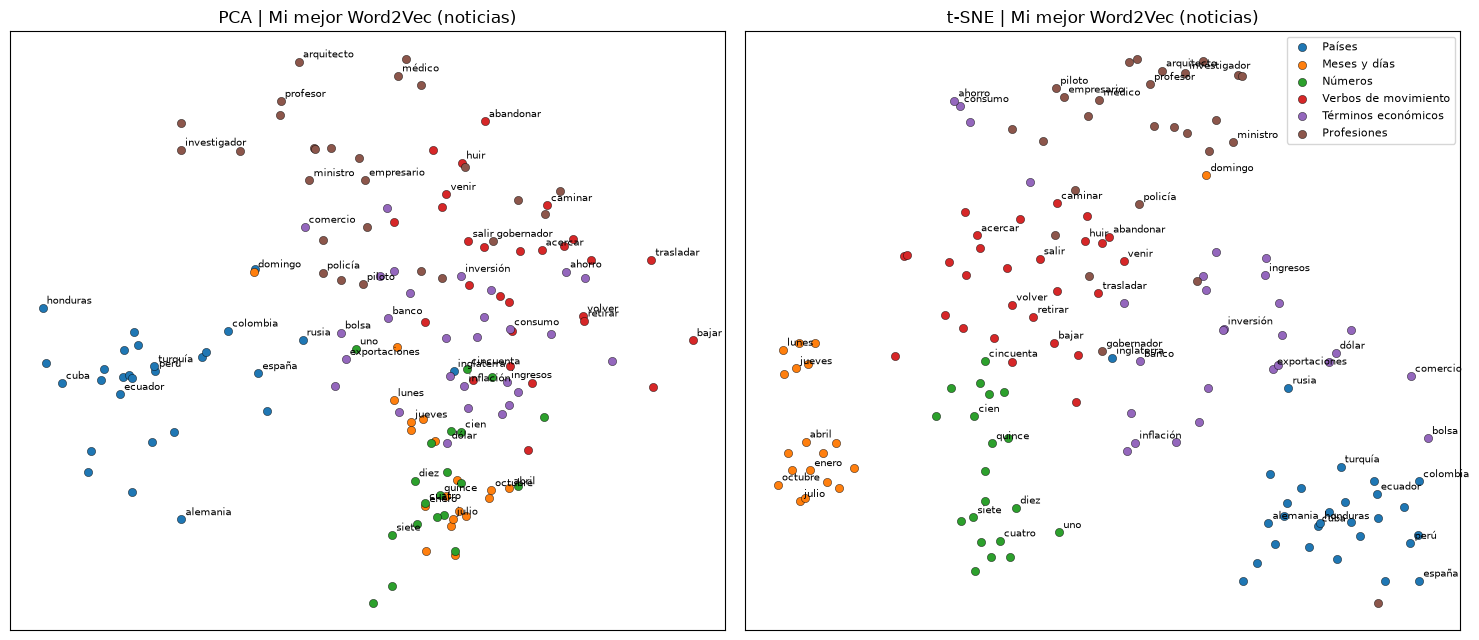

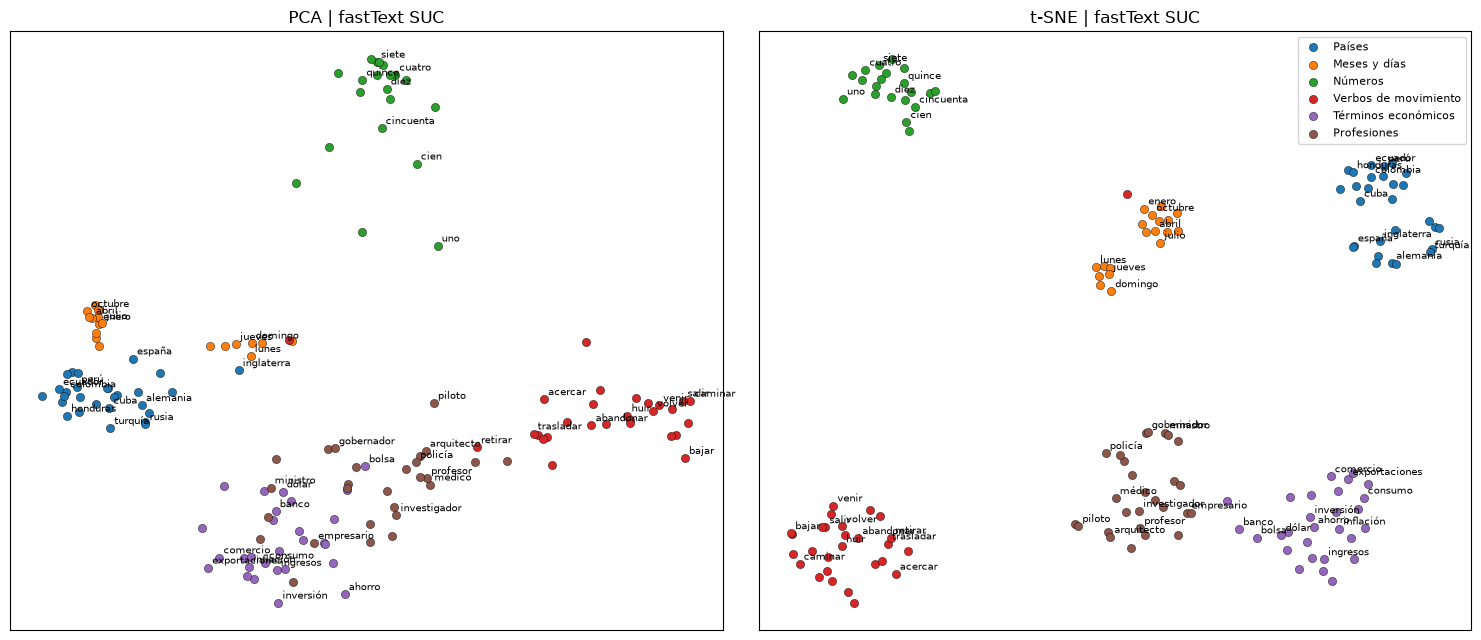

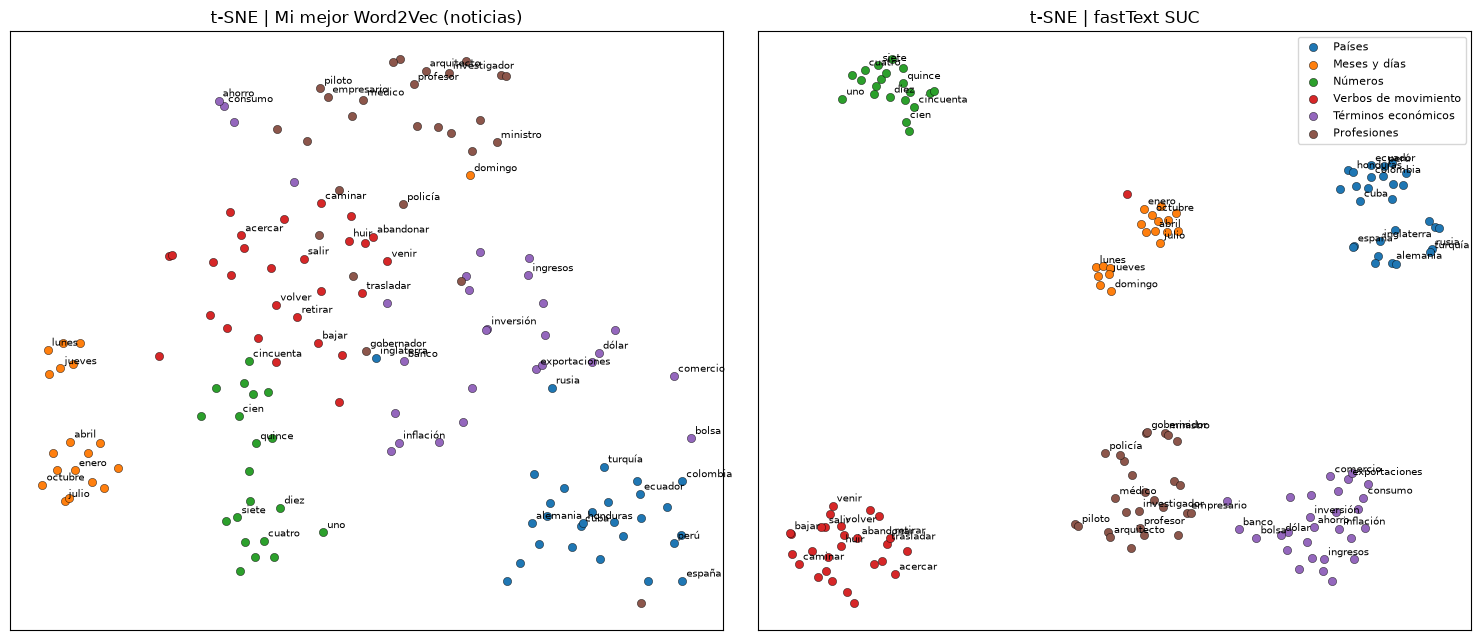

In [40]:
# Celda 40: proyecciones PCA y t-SNE para mi mejor modelo y para SUC

colores_grupos = dict(zip(grupos_candidatos.keys(), plt.cm.tab10.colors[:len(grupos_candidatos)]))
arreglo_grupos = np.array(grupos_grafica)

def proyectar(modelo, palabras):
    vectores = np.array([modelo[p] for p in palabras])
    vectores = vectores / np.linalg.norm(vectores, axis=1, keepdims=True)
    pca_2d = PCA(n_components=2, random_state=SEMILLA).fit_transform(vectores)
    tsne_2d = TSNE(n_components=2, perplexity=20, init='pca', learning_rate='auto',
                   random_state=SEMILLA).fit_transform(vectores)
    return vectores, pca_2d, tsne_2d

def dibujar(ejes, puntos, titulo, rotular_cada=3):
    for grupo, color in colores_grupos.items():
        mascara = arreglo_grupos == grupo
        ejes.scatter(puntos[mascara, 0], puntos[mascara, 1], color=color, label=grupo, s=35, edgecolors='black', linewidths=0.3)

    contador_por_grupo = Counter()
    for palabra, grupo, (x_punto, y_punto) in zip(palabras_grafica, grupos_grafica, puntos):
        if contador_por_grupo[grupo] % rotular_cada == 0:
            ejes.annotate(palabra, (x_punto, y_punto), fontsize=7, xytext=(3, 3), textcoords='offset points')
        contador_por_grupo[grupo] += 1

    ejes.set_title(titulo)
    ejes.set_xticks([])
    ejes.set_yticks([])

vectores_mejor, pca_mejor, tsne_mejor = proyectar(modelo_mejor.wv, palabras_grafica)
vectores_suc, pca_suc, tsne_suc = proyectar(suc, palabras_grafica)

for nombre_archivo, titulo_modelo, pca_2d, tsne_2d in [
        ('pca_tsne_mejor_modelo.png', 'Mi mejor Word2Vec (noticias)', pca_mejor, tsne_mejor),
        ('pca_tsne_suc.png', 'fastText SUC', pca_suc, tsne_suc)]:
    figura, ejes = plt.subplots(1, 2, figsize=(15, 6.5))
    dibujar(ejes[0], pca_2d, f"PCA | {titulo_modelo}")
    dibujar(ejes[1], tsne_2d, f"t-SNE | {titulo_modelo}")
    ejes[1].legend(loc='best', fontsize=8)
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre_archivo}", dpi=150)
    plt.show()

figura, ejes = plt.subplots(1, 2, figsize=(15, 6.5))
dibujar(ejes[0], tsne_mejor, 't-SNE | Mi mejor Word2Vec (noticias)')
dibujar(ejes[1], tsne_suc, 't-SNE | fastText SUC')
ejes[1].legend(loc='best', fontsize=8)
plt.tight_layout()
plt.savefig('figuras/tsne_comparacion.png', dpi=150)
plt.show()

In [41]:
# Celda 41: qué tan separados quedan los grupos (silueta en el espacio original y en 2D)

filas_silueta = []
for nombre, vectores, pca_2d, tsne_2d in [('Mi mejor Word2Vec', vectores_mejor, pca_mejor, tsne_mejor),
                                          ('fastText SUC', vectores_suc, pca_suc, tsne_suc)]:
    filas_silueta.append({
        'Modelo': nombre,
        'Silueta (100 dim, coseno)': round(float(silhouette_score(vectores, arreglo_grupos, metric='cosine')), 4),
        'Silueta PCA 2D': round(float(silhouette_score(pca_2d, arreglo_grupos)), 4),
        'Silueta t-SNE 2D': round(float(silhouette_score(tsne_2d, arreglo_grupos)), 4)
    })

pd.DataFrame(filas_silueta).set_index('Modelo')

,"Silueta (100 dim, coseno)",Silueta PCA 2D,Silueta t-SNE 2D
Modelo,,,
Mi mejor Word2Vec,0.1568,0.1164,0.3359
fastText SUC,0.4209,0.4376,0.7223


**Visualización**

Usé 150 palabras de 6 grupos (países 28, meses y días 19, números 20, verbos de movimiento 28, términos económicos 28 y profesiones 27), todas presentes en mi modelo y en SUC. Los grupos que descarté por no estar en alguno de los dos están listados en la tabla.

**¿Se forman los grupos esperados? ¿En qué modelo se separan mejor?**

En SUC sí se forman claramente. Números, verbos de movimiento, meses y días y países quedan en grupos bien separados, y solo términos económicos y profesiones quedan más cerca entre sí (por ejemplo banco y bolsa quedaron cerca de las profesiones). En mi modelo se forman algunos grupos, como meses, países y números, pero los verbos de movimiento quedan mezclados con números y profesiones y los términos económicos quedan regados. Esto se refleja en el índice de silueta calculado con las etiquetas de grupo, que fue 0.1568 en el espacio original, 0.1164 en PCA y 0.3359 en t-SNE para mi modelo, contra 0.4209, 0.4376 y 0.7223 para SUC. SUC separa mejor los grupos en todas las medidas.

**PCA frente a t-SNE**

PCA es una proyección lineal que conserva las direcciones de mayor varianza, así que las distancias grandes se respetan más, pero con 100 dimensiones reducidas a 2 los grupos se aplastan y se traslapan (silueta de 0.1164 y 0.4376). t-SNE intenta conservar los vecinos cercanos de cada punto, y por eso separa mucho mejor los grupos (0.3359 y 0.7223). A cambio, en t-SNE se puede confiar en que los puntos que quedan juntos sí son vecinos, pero no en la distancia entre grupos ni en el tamaño de los grupos, porque el algoritmo solo optimiza distancias locales y cambia si se cambia la semilla o la perplexity. Una distancia grande o pequeña entre dos nubes no significa que estén realmente más lejos o más cerca en el espacio original.

Las figuras se guardaron en la carpeta figuras (pca_tsne_mejor_modelo.png, pca_tsne_suc.png y tsne_comparacion.png).

# Sección 7: análisis

In [42]:
# Celda 42: la palabra "banco" y sus vecinos en los cuatro modelos

for nombre, modelo in modelos_comparados.items():
    vecinas = vecinos_modelo(modelo, 'banco', k=10)
    print(f"{nombre:14} -> {vecinas if vecinas else 'fuera del vocabulario'}")

print()
print("Vectores de «banco» en cada modelo: un solo vector por modelo")
for nombre, modelo in modelos_comparados.items():
    if 'banco' in modelo.key_to_index:
        print(f"   {nombre:14} forma: {modelo['banco'].shape}")

SVD-PPMI       -> ['bbva', 'grupo', 'central', 'colombia', 'también', 'gobierno', 'davivienda', 'mercado', 'con', 'popular']
W2V noticias   -> ['central', 'agrario', 'popular', 'república', 'pichincha', 'davivienda', 'finandina', 'invest', 'gnb', 'coopcentral']
W2V Quijote    -> ['rodar', 'acomodóse', 'ristre', 'empuñadura', 'encajó', 'desliáronle', 'grajos', 'vaina', 'túnica', 'asiendo']
fastText SUC   -> ['hipotecario', 'bancos', 'bank', 'citibank', 'monetario', 'kfw', 'bancaria', 'bancario', 'hsbc', 'fmi']

Vectores de «banco» en cada modelo: un solo vector por modelo
   SVD-PPMI       forma: (100,)
   W2V noticias   forma: (100,)
   W2V Quijote    forma: (100,)
   fastText SUC   forma: (100,)


**¿Se parecen los vecinos de SVD sobre PPMI a los de word2vec?**

Se parecen poco. Los vecinos de "empresa" son compañía, plataforma, asociación, tecnología y entidad con SVD, y startup, emergente, seré, criptomoneda y biotecnología con word2vec, y no comparten ninguno. Los de "gobierno" son república, banco, país, federal y central contra congreso, electo, plan, petro y revelara. Con "banco" sí comparten algo (central, popular y davivienda). SVD tiene vecinos más generales y mezcla palabras funcionales (también, con, se), y además solo cubre las 2,000 palabras más frecuentes, y en el Spearman dio -0.1511. Su ventaja es que es simple, rápida, determinista y usa los conteos globales completos. word2vec cubre todo el vocabulario (16,131 palabras) y aprende de palabras raras, pero depende del azar del entrenamiento y de la cantidad de texto. GloVe une los dos enfoques porque entrena vectores para reproducir los conteos globales de co-ocurrencia, como el modelo de conteos, pero con un entrenamiento tipo predictivo.

**¿Qué tan lejos quedó mi Word2Vec de fastText SUC?**

Bastante lejos. En vecinos, los de SUC son claramente más coherentes (dinero da dinerito, dineral y centavo, y empresa da compañía, constructora y subsidiaria) y los míos tienen palabras raras. En similitud, el Spearman fue 0.1055 contra 0.5235. En analogías, mi modelo cubrió 14 de 19 con 0 aciertos en el top 1 y 1 en el top 5, mientras que SUC acertó 16 de 19 en el top 1 y las 19 en el top 5. La diferencia en tamaño es enorme, 588,216 tokens contra unos 2,600 millones de palabras, o sea más de 4,000 veces más texto. No hice un experimento que separe los dos efectos, así que no puedo dar un porcentaje, pero creo que la mayor parte se debe al tamaño del corpus, porque con tan pocas apariciones por palabra casi cualquier método sale ruidoso (aunque SUC también usa subpalabras y un corpus general, no solo de noticias de economía, y eso también suma).

**¿En qué tipos de analogía funcionó mejor la aritmética vectorial?**

En SUC funcionó muy bien en género, gentilicio, singular-plural y adjetivos (3 de 3 en el top 1), regular en tiempos verbales (2 de 3) y país-capital (2 de 4, aunque las 4 en el top 5). En mis modelos falló casi en todo. El "≈" no es una igualdad, y lo comprobé sin excluir las palabras de la consulta, donde en 10 de 16 casos la primera palabra era parte de la consulta.

**Noticias frente al Quijote**

Los vecinos cambian completamente (gobierno pasa de congreso y petro a ínsula y gobierne, y empresa pasa de startup a aventura). Usar embeddings entrenados en un dominio o una época para otro trae problemas de vocabulario y de significado. De vocabulario, el Quijote solo tiene 73.92% de sus tipos en SUC, y mi modelo de noticias deja afuera casi todo lo cotidiano (12 de 20 de mis pares quedaron fuera del Quijote). De significado, las palabras cambian de sentido. Pasó algo parecido en el Lab 6 con el tagger y el reconocedor de entidades, que estaban hechos para inglés moderno, y al aplicarlos a novelas de otras épocas el desempeño cambió bastante según el libro (el F1 por token fue 0.880 en Dracula, 0.647 en Frankenstein y 0.643 en Pride and Prejudice). Es la misma idea, un modelo aprende lo que ve y solo funciona bien en textos parecidos.

**Clasificación: embeddings frente a TF-IDF**

Con el 100% del entrenamiento, en prueba, TF-IDF con regresión logística sacó accuracy 0.7953 y macro-F1 0.7048. Mi Word2Vec congelado sacó 0.8246 y 0.8049, y con fine-tuning 0.8655 y 0.8642. SUC congelado sacó 0.7895 y 0.7521 y con fine-tuning 0.8596 y 0.8184. O sea que sí superaron a TF-IDF en macro-F1 (aunque en validación el accuracy de TF-IDF, 0.8421, estuvo por encima de mi modelo congelado, 0.8129). El fine-tuning ayudó en los dos casos, y más con SUC (de 0.7521 a 0.8184 en macro-F1), lo cual tiene sentido porque los vectores generales se adaptan al vocabulario de las noticias. Con el 10% (79 documentos y 5 semillas) la diferencia se hace enorme. TF-IDF cayó a accuracy 0.5018 y macro-F1 0.2462 (desviación 0.0373), mi modelo congelado sacó 0.7298 y 0.5854 (0.0269), con fine-tuning 0.7392 y 0.6332 (0.0316), SUC congelado 0.6456 y 0.4905 y SUC con fine-tuning 0.7228 y 0.6107 (0.0520). Con pocos datos los embeddings ayudan mucho porque ya traen el significado y no tienen que aprenderlo de 79 documentos. Congelar conviene cuando hay pocos datos (menos parámetros y menos riesgo de sobreajuste, y con mi modelo la diferencia con fine-tuning fue de solo unos 0.05 en macro-F1, parecida a 1.5 veces la desviación), y el fine-tuning conviene cuando hay más datos o cuando los vectores vienen de otro dominio, como SUC. Hay que recordar que mi modelo vio el texto de prueba (sin etiquetas) al entrenar los embeddings.

**La palabra "banco"**

Tiene un solo vector en cada modelo. Sus vecinos con mi modelo son central, agrario, popular, república, pichincha, davivienda y finandina (instituciones financieras), con SUC hipotecario, bancos, bank, citibank, monetario, kfw y bancaria (también financieros), con SVD bbva, grupo, central y colombia, y con el Quijote rodar, acomodóse, ristre, empuñadura, encajó y vaina, que no tienen que ver con dinero y vienen de otros sentidos y de escenas del libro. Entonces se mezclan el banco como institución financiera, el banco como asiento, y el banco de peces o de datos, y el vector es un promedio de todos los contextos, aunque en el corpus de noticias domine el sentido financiero. Los embeddings contextuales como BERT dan un vector distinto para cada aparición, calculado con toda la oración alrededor, así que "banco" en "me senté en el banco del parque" y en "abrí una cuenta en el banco" tienen vectores distintos.

**Sistema que decide sobre personas: ¿qué auditaría?**

Primero el sesgo, con pruebas como las de la sección 8. En SUC, 22 de 24 profesiones quedaron más cerca de "hombre" que de "mujer" (sesgo promedio de 0.1344) y las analogías asocian médico con obstetricia y ginecología, o sea que el modelo aprendió estereotipos del texto. Auditaría eso mismo para género, nacionalidad, raza, edad y nombres propios. Revisaría de dónde viene el corpus de entrenamiento y si cubre a todos los grupos de forma parecida, qué pasa con palabras fuera del vocabulario y con otras variantes del español, y mediría el desempeño por grupo y no solo el promedio. Probaría con datos del propio sistema y no solo con ejemplos de laboratorio, y no dejaría que decida sola. Habría una persona que revise los casos importantes, y documentaría los límites del modelo. Mi modelo de noticias muestra otro riesgo, que con poco texto (hombre aparece 7 veces) los vectores son tan ruidosos que las medidas de sesgo no se pueden ni interpretar.

# Sección 8 (inferida): clasificación, búsqueda semántica y sesgos

**Nota:** el PDF solo llega hasta la sección 7, pero la sección 3 dice que `nn.Embedding` se usará "en la sección 8" y la sección 7 y los entregables piden clasificación, búsqueda y análisis de sesgos. Por eso esta sección está inferida. Las respuestas de la sección 7 sobre clasificación y sesgos usan estos resultados.

In [43]:
# Celda 43: partición igual a la del Laboratorio 3 (70% / 15% / 15%, estratificada, random_state=42)

df_entrenamiento, df_temporal = train_test_split(
    df_noticias, test_size=0.30, stratify=df_noticias['Type'], random_state=42)
df_validacion, df_prueba = train_test_split(
    df_temporal, test_size=0.50, stratify=df_temporal['Type'], random_state=42)

print(f"Entrenamiento: {len(df_entrenamiento)} | Validación: {len(df_validacion)} | Prueba: {len(df_prueba)}")
print("(en el Lab 3 fueron 796, 171 y 171)")

codificador_clases = LabelEncoder()
codificador_clases.fit(df_noticias['Type'])
y_entrenamiento = codificador_clases.transform(df_entrenamiento['Type'])
y_validacion = codificador_clases.transform(df_validacion['Type'])
y_prueba = codificador_clases.transform(df_prueba['Type'])
nombres_clases = list(codificador_clases.classes_)
print("Clases:", nombres_clases)

Entrenamiento: 796 | Validación: 171 | Prueba: 171
(en el Lab 3 fueron 796, 171 y 171)
Clases: ['Alianzas', 'Innovacion', 'Macroeconomia', 'Otra', 'Regulaciones', 'Reputacion', 'Sostenibilidad']


In [44]:
# Celda 44: baseline TF-IDF + Regresión Logística (igual al Laboratorio 4)

def evaluar_tfidf_rl(textos_entrenamiento, etiquetas_entrenamiento, conjuntos):
    vectorizador = TfidfVectorizer()
    matriz_entrenamiento = vectorizador.fit_transform(textos_entrenamiento)
    modelo_rl = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
    modelo_rl.fit(matriz_entrenamiento, etiquetas_entrenamiento)

    resultados = {}
    for nombre_conjunto, (textos, etiquetas) in conjuntos.items():
        predicciones = modelo_rl.predict(vectorizador.transform(textos))
        resultados[nombre_conjunto] = {'accuracy': accuracy_score(etiquetas, predicciones),
                                       'f1_macro': f1_score(etiquetas, predicciones, average='macro')}
    return resultados

conjuntos_evaluacion_texto = {
    'validacion': (df_validacion['texto_normalizado'], y_validacion),
    'prueba': (df_prueba['texto_normalizado'], y_prueba)
}

resultado_tfidf_100 = evaluar_tfidf_rl(df_entrenamiento['texto_normalizado'], y_entrenamiento, conjuntos_evaluacion_texto)

for conjunto, metricas in resultado_tfidf_100.items():
    print(f"TF-IDF + RL (100% de entrenamiento) | {conjunto:10} accuracy = {metricas['accuracy']:.4f} | macro-F1 = {metricas['f1_macro']:.4f}")

TF-IDF + RL (100% de entrenamiento) | validacion accuracy = 0.8421 | macro-F1 = 0.7216
TF-IDF + RL (100% de entrenamiento) | prueba     accuracy = 0.7953 | macro-F1 = 0.7048


In [45]:
# Celda 45: clasificador con nn.EmbeddingBag (mean) y función de entrenamiento

EPOCAS_CLASIFICADOR = 40
TAMANO_LOTE = 32
TASA_APRENDIZAJE = 0.01

class ClasificadorBolsa(nn.Module):

    def __init__(self, matriz_embeddings, numero_clases, congelar):
        super().__init__()
        self.embedding = nn.EmbeddingBag.from_pretrained(
            torch.tensor(matriz_embeddings, dtype=torch.float32), freeze=congelar, mode='mean')
        self.capa_salida = nn.Linear(matriz_embeddings.shape[1], numero_clases)

    def forward(self, ids, inicios):
        return self.capa_salida(self.embedding(ids, inicios))

def empaquetar(lista_de_ids):
    ids = torch.tensor([i for ids_doc in lista_de_ids for i in ids_doc], dtype=torch.long)
    largos = torch.tensor([len(ids_doc) for ids_doc in lista_de_ids])
    inicios = torch.cumsum(largos, dim=0) - largos
    return ids, inicios

def entrenar_clasificador(matriz_embeddings, ids_entrenamiento, etiquetas_entrenamiento, conjuntos,
                          congelar, semilla, epocas=EPOCAS_CLASIFICADOR):
    torch.manual_seed(semilla)
    modelo = ClasificadorBolsa(matriz_embeddings, len(nombres_clases), congelar)
    optimizador = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=TASA_APRENDIZAJE)
    funcion_perdida = nn.CrossEntropyLoss()
    generador = torch.Generator().manual_seed(semilla)
    etiquetas_tensor = torch.tensor(etiquetas_entrenamiento, dtype=torch.long)

    for _ in range(epocas):
        modelo.train()
        orden = torch.randperm(len(ids_entrenamiento), generator=generador).tolist()
        for inicio in range(0, len(orden), TAMANO_LOTE):
            lote = orden[inicio:inicio + TAMANO_LOTE]
            ids, inicios = empaquetar([ids_entrenamiento[i] for i in lote])
            perdida = funcion_perdida(modelo(ids, inicios), etiquetas_tensor[lote])
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()

    modelo.eval()
    resultados = {}
    with torch.no_grad():
        for nombre_conjunto, (ids_conjunto, etiquetas) in conjuntos.items():
            ids, inicios = empaquetar(ids_conjunto)
            predicciones = modelo(ids, inicios).argmax(dim=1).numpy()
            resultados[nombre_conjunto] = {'accuracy': accuracy_score(etiquetas, predicciones),
                                           'f1_macro': f1_score(etiquetas, predicciones, average='macro')}
    return resultados

print("Clasificador definido")

Clasificador definido


In [46]:
# Celda 46: vocabulario y documentos como listas de ids (sin stopwords) para cada fuente de vectores

tokens_por_documento = [[token for oracion in documento for token in oracion] for documento in documentos_noticias]
tokens_sin_stopwords = [[token for token in tokens if token not in stop_es] for tokens in tokens_por_documento]

print("Tokens promedio por documento (sin stopwords):", round(np.mean([len(t) for t in tokens_sin_stopwords]), 1))

def preparar_fuente(modelo_kv, nombre):
    vocabulario_noticias = sorted({token for tokens in tokens_sin_stopwords for token in tokens})
    vocabulario_fuente = [p for p in vocabulario_noticias if p in modelo_kv.key_to_index]
    indice = {p: i for i, p in enumerate(vocabulario_fuente)}
    matriz = np.array([modelo_kv[p] for p in vocabulario_fuente], dtype=np.float32)
    ids_documentos = [[indice[t] for t in tokens if t in indice] for tokens in tokens_sin_stopwords]

    cobertura = sum(len(ids) for ids in ids_documentos) / sum(len(t) for t in tokens_sin_stopwords) * 100
    print(f"{nombre}: {len(vocabulario_fuente)} palabras en la tabla | {cobertura:.1f}% de los tokens de las noticias tienen vector")
    return matriz, ids_documentos

fuentes_embeddings = {'Mi Word2Vec': preparar_fuente(modelo_mejor.wv, 'Mi Word2Vec')}
if suc is not None:
    fuentes_embeddings['fastText SUC'] = preparar_fuente(suc, 'fastText SUC')

posiciones_entrenamiento = [df_noticias.index.get_loc(i) for i in df_entrenamiento.index]
posiciones_validacion = [df_noticias.index.get_loc(i) for i in df_validacion.index]
posiciones_prueba = [df_noticias.index.get_loc(i) for i in df_prueba.index]

Tokens promedio por documento (sin stopwords): 271.4
Mi Word2Vec: 15934 palabras en la tabla | 96.0% de los tokens de las noticias tienen vector
fastText SUC: 24712 palabras en la tabla | 97.8% de los tokens de las noticias tienen vector


In [47]:
# Celda 47: resultados con el 100% de los datos de entrenamiento

filas_100 = []

for nombre_fuente, (matriz, ids_documentos) in fuentes_embeddings.items():
    ids_entrenamiento = [ids_documentos[i] for i in posiciones_entrenamiento]
    conjuntos = {'validacion': ([ids_documentos[i] for i in posiciones_validacion], y_validacion),
                 'prueba': ([ids_documentos[i] for i in posiciones_prueba], y_prueba)}

    for congelar in (True, False):
        resultado = entrenar_clasificador(matriz, ids_entrenamiento, y_entrenamiento, conjuntos,
                                          congelar=congelar, semilla=SEMILLA)
        filas_100.append({
            'Modelo': f"{nombre_fuente} ({'congelado' if congelar else 'fine-tuning'})",
            'Accuracy validación': round(resultado['validacion']['accuracy'], 4),
            'Macro-F1 validación': round(resultado['validacion']['f1_macro'], 4),
            'Accuracy prueba': round(resultado['prueba']['accuracy'], 4),
            'Macro-F1 prueba': round(resultado['prueba']['f1_macro'], 4)
        })

filas_100.insert(0, {
    'Modelo': 'TF-IDF + Regresión Logística',
    'Accuracy validación': round(resultado_tfidf_100['validacion']['accuracy'], 4),
    'Macro-F1 validación': round(resultado_tfidf_100['validacion']['f1_macro'], 4),
    'Accuracy prueba': round(resultado_tfidf_100['prueba']['accuracy'], 4),
    'Macro-F1 prueba': round(resultado_tfidf_100['prueba']['f1_macro'], 4)
})

tabla_resultados_100 = pd.DataFrame(filas_100).set_index('Modelo')
tabla_resultados_100

,Accuracy validación,Macro-F1 validación,Accuracy prueba,Macro-F1 prueba
Modelo,,,,
TF-IDF + Regresión Logística,0.8421,0.7216,0.7953,0.7048
Mi Word2Vec (congelado),0.8129,0.7556,0.8246,0.8049
Mi Word2Vec (fine-tuning),0.8538,0.7960,0.8655,0.8642
fastText SUC (congelado),0.7485,0.6858,0.7895,0.7521
fastText SUC (fine-tuning),0.8480,0.7905,0.8596,0.8184


In [48]:
# Celda 48: resultados con solo el 10% de los datos de entrenamiento (5 semillas)

SEMILLAS_10 = [0, 1, 2, 3, 4]
metricas_10 = {}

for semilla in SEMILLAS_10:
    posiciones_sub, _ = train_test_split(np.arange(len(df_entrenamiento)), train_size=0.10,
                                         stratify=y_entrenamiento, random_state=semilla)
    y_sub = y_entrenamiento[posiciones_sub]

    resultado_tfidf = evaluar_tfidf_rl(df_entrenamiento['texto_normalizado'].iloc[posiciones_sub], y_sub,
                                       {'prueba': (df_prueba['texto_normalizado'], y_prueba)})
    metricas_10.setdefault('TF-IDF + Regresión Logística', []).append(
        (resultado_tfidf['prueba']['accuracy'], resultado_tfidf['prueba']['f1_macro']))

    for nombre_fuente, (matriz, ids_documentos) in fuentes_embeddings.items():
        ids_sub = [ids_documentos[posiciones_entrenamiento[i]] for i in posiciones_sub]
        conjuntos = {'prueba': ([ids_documentos[i] for i in posiciones_prueba], y_prueba)}
        for congelar in (True, False):
            resultado = entrenar_clasificador(matriz, ids_sub, y_sub, conjuntos, congelar=congelar, semilla=semilla)
            nombre = f"{nombre_fuente} ({'congelado' if congelar else 'fine-tuning'})"
            metricas_10.setdefault(nombre, []).append((resultado['prueba']['accuracy'], resultado['prueba']['f1_macro']))

print("Documentos de entrenamiento con el 10%:", len(posiciones_sub))
print("Documentos por clase en la última submuestra:", {clase: int(n) for clase, n in zip(nombres_clases, np.bincount(y_sub))})

filas_10 = []
for nombre, valores in metricas_10.items():
    valores = np.array(valores)
    filas_10.append({
        'Modelo': nombre,
        'Accuracy prueba (promedio)': round(valores[:, 0].mean(), 4),
        'Accuracy (desv. est.)': round(valores[:, 0].std(), 4),
        'Macro-F1 prueba (promedio)': round(valores[:, 1].mean(), 4),
        'Macro-F1 (desv. est.)': round(valores[:, 1].std(), 4)
    })

tabla_resultados_10 = pd.DataFrame(filas_10).set_index('Modelo')
tabla_resultados_10

Documentos de entrenamiento con el 10%: 79
Documentos por clase en la última submuestra: {'Alianzas': 17, 'Innovacion': 10, 'Macroeconomia': 22, 'Otra': 9, 'Regulaciones': 10, 'Reputacion': 2, 'Sostenibilidad': 9}


,Accuracy prueba (promedio),Accuracy (desv. est.),Macro-F1 prueba (promedio),Macro-F1 (desv. est.)
Modelo,,,,
TF-IDF + Regresión Logística,0.5018,0.0283,0.2462,0.0373
Mi Word2Vec (congelado),0.7298,0.0183,0.5854,0.0269
Mi Word2Vec (fine-tuning),0.7392,0.0297,0.6332,0.0316
fastText SUC (congelado),0.6456,0.0250,0.4905,0.0338
fastText SUC (fine-tuning),0.7228,0.0227,0.6107,0.0520


In [49]:
# Celda 49: búsqueda semántica: promedio de vectores frente a TF-IDF

def vector_promedio(tokens, modelo_kv):
    vectores = [modelo_kv[t] for t in tokens if t in modelo_kv.key_to_index and t not in stop_es]
    if not vectores:
        return np.zeros(modelo_kv.vector_size)
    return np.mean(vectores, axis=0)

def normalizar_filas(matriz):
    normas = np.linalg.norm(matriz, axis=1, keepdims=True)
    normas[normas == 0] = 1
    return matriz / normas

matriz_docs_w2v = normalizar_filas(np.array([vector_promedio(t, modelo_mejor.wv) for t in tokens_por_documento]))

vectorizador_busqueda = TfidfVectorizer()
matriz_docs_tfidf = vectorizador_busqueda.fit_transform(df_noticias['texto_normalizado'])

def normalizar_consulta_lab1(texto):
    tokens = [t.lower() for t in word_tokenize(texto, language='spanish')]
    tokens = [t for t in tokens if t not in puntuacion and any(c.isalnum() for c in t) and t not in stop_es]
    return ' '.join(tok.lemma_ for tok in nlp_lab1(' '.join(tokens)))

def buscar(consulta, k=10):
    tokens_consulta = [t for t in (x.lower() for x in word_tokenize(consulta, language='spanish')) if patron_token_valido.match(t)]
    vector_consulta = normalizar_filas(vector_promedio(tokens_consulta, modelo_mejor.wv).reshape(1, -1))
    puntajes_w2v = (matriz_docs_w2v @ vector_consulta.T).ravel()

    vector_tfidf = vectorizador_busqueda.transform([normalizar_consulta_lab1(consulta)])
    puntajes_tfidf = cosine_similarity(vector_tfidf, matriz_docs_tfidf).ravel()

    return np.argsort(-puntajes_w2v)[:k], np.argsort(-puntajes_tfidf)[:k]

consultas = [
    ('inflación y aumento de precios al consumidor', 'Macroeconomia'),
    ('alianza estratégica entre dos empresas', 'Alianzas'),
    ('nueva tecnología e innovación digital', 'Innovacion'),
    ('nuevas normas y regulación del gobierno', 'Regulaciones'),
    ('cambio climático y energía sostenible', 'Sostenibilidad')
]

filas_busqueda = []
for consulta, categoria_esperada in consultas:
    ids_w2v, ids_tfidf = buscar(consulta)
    filas_busqueda.append({
        'Consulta': consulta,
        'Categoría esperada': categoria_esperada,
        'Precisión@10 promedio de vectores': np.mean(df_noticias['Type'].iloc[ids_w2v].values == categoria_esperada),
        'Precisión@10 TF-IDF': np.mean(df_noticias['Type'].iloc[ids_tfidf].values == categoria_esperada),
        'Docs en común en el top 10': len(set(ids_w2v) & set(ids_tfidf))
    })

display(pd.DataFrame(filas_busqueda).set_index('Consulta'))

for consulta, _ in [consultas[0], consultas[2], consultas[4]]:
    ids_w2v, ids_tfidf = buscar(consulta, k=3)
    print("=" * 100)
    print("Consulta:", consulta)
    for etiqueta, ids in [('Promedio de vectores', ids_w2v), ('TF-IDF', ids_tfidf)]:
        print(f"  {etiqueta}")
        for i in ids:
            print(f"    [{df_noticias['Type'].iloc[i]}] {df_noticias['news'].iloc[i][:140]}...")

,Categoría esperada,Precisión@10 promedio de vectores,Precisión@10 TF-IDF,Docs en común en el top 10
Consulta,,,,
inflación y aumento de precios al consumidor,Macroeconomia,1.0,1.0,4
alianza estratégica entre dos empresas,Alianzas,0.9,0.9,3
nueva tecnología e innovación digital,Innovacion,0.7,0.4,2
nuevas normas y regulación del gobierno,Regulaciones,1.0,1.0,1
cambio climático y energía sostenible,Sostenibilidad,0.7,0.8,3


Consulta: inflación y aumento de precios al consumidor
  Promedio de vectores
    [Macroeconomia] Los precios pagados a los productores estadounidenses subieron en junio más de lo previsto una señal de que está aumentando la presión sobre...
    [Macroeconomia] La inflación en Canadá se aceleró a su nivel más alto en una década en lo que los legisladores dicen que solo será un aumento temporal de lo...
    [Macroeconomia] Las ganancias de los precios al consumidor en EE.UU. se aceleraron en febrero a un nuevo máximo en 40 años en consonancia con la rápida infl...
  TF-IDF
    [Macroeconomia] Los precios al consumidor de EE.UU. subieron en enero más de lo esperado lo que representa un golpe mayor para los cheques de pago de los es...
    [Macroeconomia] La inflación en Canadá se aceleró a su nivel más alto en una década en lo que los legisladores dicen que solo será un aumento temporal de lo...
    [Macroeconomia] La inflación del Reino Unido se aceleró más de lo esperado el mes pasado 

In [50]:
# Celda 50: sesgo de género: profesiones frente a hombre y mujer en SUC y en mi modelo

profesiones = ['médico', 'enfermero', 'ingeniero', 'profesor', 'abogado', 'secretario', 'cocinero', 'policía',
               'científico', 'presidente', 'ministro', 'director', 'gerente', 'empresario', 'periodista', 'juez',
               'soldado', 'economista', 'banquero', 'analista', 'investigador', 'maestro', 'conductor', 'contador']

modelos_sesgo = {'Mi Word2Vec (noticias)': modelo_mejor.wv}
if suc is not None:
    modelos_sesgo['fastText SUC'] = suc

print("Frecuencia en el corpus de noticias -> hombre:", frecuencias_noticias['hombre'], "| mujer:", frecuencias_noticias['mujer'])

tablas_sesgo = {}
for nombre, modelo in modelos_sesgo.items():
    filas = []
    for profesion in profesiones:
        if profesion in modelo.key_to_index:
            cos_hombre = coseno(modelo[profesion], modelo['hombre'])
            cos_mujer = coseno(modelo[profesion], modelo['mujer'])
            filas.append({'Profesión': profesion, 'Coseno con hombre': round(cos_hombre, 4),
                          'Coseno con mujer': round(cos_mujer, 4), 'Sesgo (hombre - mujer)': round(cos_hombre - cos_mujer, 4)})
    tablas_sesgo[nombre] = pd.DataFrame(filas).set_index('Profesión').sort_values('Sesgo (hombre - mujer)', ascending=False)

    print(f"\n{nombre}: {len(tablas_sesgo[nombre])} de {len(profesiones)} profesiones en el vocabulario")
    display(tablas_sesgo[nombre])
    sesgos = tablas_sesgo[nombre]['Sesgo (hombre - mujer)']
    print(f"Sesgo promedio: {sesgos.mean():.4f} | profesiones más cerca de «hombre»: {int((sesgos > 0).sum())} de {len(sesgos)}")

Frecuencia en el corpus de noticias -> hombre: 7 | mujer: 25

Mi Word2Vec (noticias): 20 de 24 profesiones en el vocabulario


,Coseno con hombre,Coseno con mujer,Sesgo (hombre - mujer)
Profesión,,,
conductor,0.3221,0.0080,0.3141
periodista,0.5007,0.3049,0.1957
empresario,0.5635,0.3760,0.1875
maestro,0.4401,0.2675,0.1726
juez,0.5072,0.3377,0.1695
secretario,0.3541,0.1966,0.1575
científico,0.4532,0.3216,0.1315
banquero,0.3264,0.2166,0.1097
profesor,0.4088,0.3104,0.0984


Sesgo promedio: 0.0964 | profesiones más cerca de «hombre»: 18 de 20

fastText SUC: 24 de 24 profesiones en el vocabulario


,Coseno con hombre,Coseno con mujer,Sesgo (hombre - mujer)
Profesión,,,
soldado,0.7038,0.4088,0.2950
maestro,0.4495,0.1826,0.2669
cocinero,0.5581,0.3214,0.2367
conductor,0.5069,0.2728,0.2341
contador,0.3277,0.1106,0.2171
ingeniero,0.3853,0.1918,0.1935
investigador,0.4229,0.2366,0.1863
banquero,0.5432,0.3591,0.1841
científico,0.3856,0.2149,0.1708


Sesgo promedio: 0.1344 | profesiones más cerca de «hombre»: 22 de 24


In [51]:
# Celda 51: sesgo de género: analogías hombre : profesión :: mujer : ?

profesiones_analogia = ['médico', 'ingeniero', 'profesor', 'presidente', 'director', 'empresario', 'científico']

for nombre, modelo in modelos_sesgo.items():
    print(nombre)
    for profesion in profesiones_analogia:
        if all(p in modelo.key_to_index for p in ('hombre', profesion, 'mujer')):
            vecinas = modelo.most_similar(positive=[profesion, 'mujer'], negative=['hombre'], topn=5)
            print(f"   hombre : {profesion} :: mujer : ?  ->", [p for p, _ in vecinas])
        else:
            print(f"   hombre : {profesion} :: mujer : ?  -> fuera del vocabulario")
    print()

Mi Word2Vec (noticias)
   hombre : médico :: mujer : ?  -> ['exclusivo', 'daviplata', 'pyme', 'front', 'sanitas']
   hombre : ingeniero :: mujer : ?  -> ['matemáticas', 'científica', 'estudió', 'arquitecto', 'rosalía']
   hombre : profesor :: mujer : ?  -> ['científica', 'front', 'school', 'jesús', 'facultad']
   hombre : presidente :: mujer : ?  -> ['mauricio', 'ofrecerá', 'asobancaria', 'aeb', '795']
   hombre : director :: mujer : ?  -> ['camilo', 'hernán', 'carboni', 'western', 'investment']
   hombre : empresario :: mujer : ?  -> ['sistemleri', 'taxonomía', 'elektrikli', 'sustentabilidad', 'unificar']
   hombre : científico :: mujer : ?  -> ['matemáticas', 'máster', 'front', 'ingeniero', 'programación']

fastText SUC
   hombre : médico :: mujer : ?  -> ['obstetricia', 'ginecóloga', 'ginecología', 'pediatría', 'obstetra']
   hombre : ingeniero :: mujer : ?  -> ['ingeniera', 'arquitecta', 'pedagoga', 'ingeniería', 'diplomada']
   hombre : profesor :: mujer : ?  -> ['profesora', 'cat

**Nota sobre la sección 8**

Para clasificar usé la misma partición del Lab 3 (796, 171 y 171 documentos, random_state 42) y el mismo baseline del Lab 4 (TF-IDF con regresión logística), y me dio los mismos valores de validación que en ese lab (accuracy 0.8421 y macro-F1 0.7216). Los embeddings se pasan por nn.EmbeddingBag con mode mean (sin stopwords) y una capa lineal. Los hiperparámetros del clasificador (40 épocas, lote de 32, Adam con tasa 0.01) los fijé de antemano y no los ajusté. Hay que tener en cuenta que mi Word2Vec se entrenó con el texto de todos los documentos, incluidos los de prueba, aunque sin usar las etiquetas, y eso le da una pequeña ventaja frente a SUC y TF-IDF. Con el 10% (79 documentos, solo 2 de Reputacion en la última muestra) repetí con 5 semillas y reporto promedio y desviación.

**Búsqueda semántica**

Con 5 consultas calculé qué proporción de los 10 primeros resultados tiene la categoría esperada. El promedio de vectores y TF-IDF empataron en inflación (1.0 y 1.0), alianza (0.9 y 0.9) y regulación (1.0 y 1.0). Con "nueva tecnología e innovación digital" ganó el promedio de vectores (0.7 contra 0.4) y con "cambio climático y energía sostenible" ganó TF-IDF (0.8 contra 0.7). Los dos métodos comparten pocos documentos en el top 10 (entre 1 y 4), así que encuentran cosas distintas.

**Sesgos de género**

Medí el coseno de 24 profesiones con "hombre" y con "mujer". En SUC el sesgo promedio (coseno con hombre menos coseno con mujer) fue 0.1344 y 22 de 24 profesiones quedaron más cerca de "hombre". Las más inclinadas fueron soldado (0.2950), maestro (0.2669), cocinero (0.2367) y conductor (0.2341), y solo secretario (-0.0442) y policía (-0.0675) quedaron más cerca de "mujer". Esta medida tiene el problema de que "hombre" también se usa como "ser humano", así que casi todo queda más cerca de "hombre", y lo más útil es comparar las profesiones entre sí. En mi modelo de noticias salió 0.0964 con 18 de 20 más cerca de "hombre", pero "hombre" aparece solo 7 veces en el corpus y "mujer" 25, así que esos vectores casi no son confiables. En las analogías hombre : profesión :: mujer : ? SUC devolvió cosas como ingeniera, profesora, presidenta y directora (formas femeninas), pero también cosas más sesgadas, como médico, que dio obstetricia, ginecóloga, ginecología y pediatría, y científico, que dio investigadora, inmunología, bioética y gerontología. Mi modelo de noticias devolvió palabras sin sentido (exclusivo, daviplata, pyme, front, sanitas).

In [52]:
# Celda 52: resumen de archivos generados

archivos_generados = ['vectores_svd_ppmi.kv', 'mejor_modelo_noticias.kv', 'modelo_quijote.kv',
                      'figuras/pca_tsne_mejor_modelo.png', 'figuras/pca_tsne_suc.png', 'figuras/tsne_comparacion.png']

for archivo in archivos_generados:
    print(f"{archivo:40} {os.path.getsize(archivo) / 1e6:8.2f} MB")

vectores_svd_ppmi.kv                         0.84 MB
mejor_modelo_noticias.kv                     7.02 MB
modelo_quijote.kv                            5.00 MB
figuras/pca_tsne_mejor_modelo.png            0.20 MB
figuras/pca_tsne_suc.png                     0.19 MB
figuras/tsne_comparacion.png                 0.20 MB
